# 🍷 Wine Quality Predictor — Deep Learning *Classification & Regression*

**Prédire la qualité d'un vin (note de 3 à 9) à partir de 11 mesures physico-chimiques.**
Dataset : [Wine Quality Dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset) — 6 497 vins rouges et blancs.

| | |
|---|---|
| **Tâches** | classification 7 classes · classification 3 classes · régression |
| **Modèles** | MLP Keras (TensorFlow) + baselines scikit-learn |
| **Données** | 6 497 lignes × 13 colonnes → **25 features** après feature engineering |
| **Point clé** | les **ratios œnologiques** (`sulphates / chlorides`, `alcohol / density`…) portent plus d'information que les variables brutes |

---

### 🎯 Objectifs

1. **Auditer** les données (valeurs manquantes, doublons, asymétrie, déséquilibre des classes).
2. **Feature engineering** : construire des variables qui traduisent un raisonnement œnologique (équilibre acide, soufre actif, rapport sucre/alcool…).
3. **Visualiser** chaque signal important et l'**interpréter** en langage métier.
4. **Comparer** trois formulations du même problème (7 classes, 3 classes, régression) et les situer face à des **baselines** solides.
5. **Expliquer** les résultats (courbes d'apprentissage, matrices de confusion, importances par permutation) et en tirer des conclusions honnêtes.

---

### 🧭 Sommaire

| § | Contenu |
|---|---|
| 1 | Environnement & reproductibilité |
| 2 | Chargement et audit du jeu de données |
| 3 | Nettoyage (doublons, valeurs manquantes) |
| 4 | **Feature engineering** (14 variables dérivées) |
| 5 | Analyse exploratoire & visualisations interprétées |
| 6 | Importance des variables (information mutuelle, forêt aléatoire) |
| 7 | Découpage train / validation / test **sans fuite** |
| 8 | Baselines scikit-learn |
| 9 | MLP — classification 7 classes |
| 10 | MLP — classification 3 classes |
| 11 | MLP — régression |
| 12 | Interprétabilité (importance par permutation) |
| 13 | Recherche d'hyperparamètres |
| 14 | Synthèse comparative |
| 15 | Conclusion, limites & perspectives |

## 1. Environnement & reproductibilité

On fixe **toutes** les graines aléatoires (Python, NumPy, TensorFlow) : sans cela, deux exécutions donnent des réseaux différents et les conclusions deviennent impossibles à vérifier.

In [1]:
%matplotlib inline

# --- Configuration de l'environnement ---
import os, random, warnings

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # logs TensorFlow allégés
os.environ.setdefault("PYTHONHASHSEED", "42")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Charte graphique « vin »
RED, GOLD, INK, BLUE, GREEN = "#8B1E3F", "#C9A227", "#2B2B2B", "#4C6E91", "#6B8E5E"
PALETTE = [RED, GOLD, BLUE, GREEN, "#B56576", "#8E6C88"]

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.dpi": 100,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
print("tensorflow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "aucun → CPU")

pandas     : 2.1.4
numpy      : 1.26.4
tensorflow : 2.17.0
GPU        : aucun → CPU


## 2. Chargement et audit du jeu de données

Un jeu de données ne s'utilise pas avant d'avoir répondu à quatre questions : **quelle taille ? quels types ? qu'est-ce qui manque ? qu'est-ce qui est dupliqué ?**

In [2]:
raw = pd.read_csv("winequality.csv")
print(f"Dimensions : {raw.shape[0]:,} lignes × {raw.shape[1]} colonnes")
raw.head(10)

Dimensions : 6,497 lignes × 13 colonnes


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.000,0.270,0.360,20.700,0.045,45.000,170.000,1.001,3.000,0.450,8.800,6
1,white,6.300,0.300,0.340,1.600,0.049,14.000,132.000,0.994,3.300,0.490,9.500,6
2,white,8.100,0.280,0.400,6.900,0.050,30.000,97.000,0.995,3.260,0.440,10.100,6
3,white,7.200,0.230,0.320,8.500,0.058,47.000,186.000,0.996,3.190,0.400,9.900,6
4,white,7.200,0.230,0.320,8.500,0.058,47.000,186.000,0.996,3.190,0.400,9.900,6
5,white,8.100,0.280,0.400,6.900,0.050,30.000,97.000,0.995,3.260,0.440,10.100,6
6,white,6.200,0.320,0.160,7.000,0.045,30.000,136.000,0.995,3.180,0.470,9.600,6
7,white,7.000,0.270,0.360,20.700,0.045,45.000,170.000,1.001,3.000,0.450,8.800,6
8,white,6.300,0.300,0.340,1.600,0.049,14.000,132.000,0.994,3.300,0.490,9.500,6
9,white,8.100,0.220,0.430,1.500,0.044,28.000,129.000,0.994,3.220,0.450,11.000,6


In [3]:
audit = pd.DataFrame({
    "type_pandas": raw.dtypes.astype(str),
    "valeurs_uniques": raw.nunique(),
    "manquants": raw.isna().sum(),
})
display(audit)

print("\nColonnes catégorielles :", list(raw.select_dtypes(exclude="number").columns))
print("Colonnes numériques   :", len(raw.select_dtypes("number").columns))

,type_pandas,valeurs_uniques,manquants
type,object,2,0
fixed acidity,float64,106,10
volatile acidity,float64,187,8
citric acid,float64,89,3
residual sugar,float64,316,2
chlorides,float64,214,2
free sulfur dioxide,float64,135,0
total sulfur dioxide,float64,276,0
density,float64,998,0
pH,float64,108,9



Colonnes catégorielles : ['type']
Colonnes numériques   : 12


In [4]:
na = pd.DataFrame({
    "manquants": raw.isna().sum(),
    "pct_ligne": (raw.isna().mean() * 100).round(2),
})
na = na[na["manquants"] > 0].sort_values("manquants", ascending=False)

print(f"Cellules manquantes : {int(raw.isna().sum().sum())} "
      f"({raw.isna().mean().mean() * 100:.3f} % des cellules) "
      f"réparties sur {raw.isna().any(axis=1).sum()} lignes")
display(na)

print("\nLignes incomplètes par type de vin :")
display(raw[raw.isna().any(axis=1)]["type"].value_counts().to_frame("lignes incomplètes"))

Cellules manquantes : 38 (0.045 % des cellules) réparties sur 34 lignes


,manquants,pct_ligne
fixed acidity,10,0.150
pH,9,0.140
volatile acidity,8,0.120
sulphates,4,0.060
citric acid,3,0.050
residual sugar,2,0.030
chlorides,2,0.030



Lignes incomplètes par type de vin :


,lignes incomplètes
type,
white,28
red,6


### 🧪 Interprétation — valeurs manquantes

* **38 cellules manquantes** seulement (≈ **0,05 %** du tableau), concentrées sur `fixed acidity`, `pH`, `volatile acidity` et `sulphates`.
* Elles touchent **34 lignes**, majoritairement des vins **blancs** (28 contre 6).

👉 À ce niveau de rareté, **supprimer les lignes serait du gaspillage et de l'imputation risquée**. On garde les lignes et on impute par la **médiane** — robuste aux distributions asymétriques de ce dataset, contrairement à la moyenne utilisée dans la version précédente, qui aurait été tirée vers le haut par les valeurs extrêmes de `chlorides` (max 0,611 pour une médiane de 0,047).

In [5]:
dup = raw.duplicated(keep="first")
print(f"Lignes dupliquées (sur les 13 colonnes) : {dup.sum():,} ({dup.mean() * 100:.1f} %)")
print(f"Lignes restantes après suppression       : {len(raw.drop_duplicates()):,}")

par_type = (raw.assign(doublon=dup)
              .groupby("type")
              .agg(lignes=("quality", "size"), doublons=("doublon", "sum")))
par_type["pct_doublons"] = (par_type["doublons"] / par_type["lignes"] * 100).round(1)
display(par_type)

Lignes dupliquées (sur les 13 colonnes) : 1,168 (18.0 %)
Lignes restantes après suppression       : 5,329


,lignes,doublons,pct_doublons
type,,,
red,1599,240,15.000
white,4898,928,18.900


### 🧪 Interprétation — doublons

**1 168 lignes (18 %)** sont des copies exactes d'une autre ligne sur les 13 colonnes.

Trois conséquences :

1. **Fuite train/test** : un vin dupliqué peut se retrouver dans le train *et* dans le test. Le modèle « reconnaît » alors une ligne déjà vue et les scores deviennent artificiellement bons.
2. **Pondération biaisée** : les vins sur-représentés pèsent plus lourd dans l'apprentissage que leur importance réelle.
3. Ces doublons sont **attendus** : plusieurs lots de vin peuvent partager des mesures arrondies identiques. Les supprimer est le compromis standard sur ce dataset.

👉 On supprime les doublons : **5 329 vins uniques** restent pour la modélisation.

In [6]:
num = raw.select_dtypes("number")
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
outliers = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()

desc = num.describe().T[["mean", "std", "min", "50%", "max"]]
desc["skew"] = num.skew()
desc["outliers_IQR"] = outliers
desc["pct_outliers"] = (outliers / len(raw) * 100).round(1)
display(desc.round(3))

,mean,std,min,50%,max,skew,outliers_IQR,pct_outliers
fixed acidity,7.217,1.297,3.800,7.000,15.900,1.723,357,5.500
volatile acidity,0.340,0.165,0.080,0.290,1.580,1.496,376,5.800
citric acid,0.319,0.145,0.000,0.310,1.660,0.473,508,7.800
residual sugar,5.444,4.758,0.600,3.000,65.800,1.435,118,1.800
chlorides,0.056,0.035,0.009,0.047,0.611,5.400,286,4.400
free sulfur dioxide,30.525,17.749,1.000,29.000,289.000,1.220,62,1.000
total sulfur dioxide,115.745,56.522,6.000,118.000,440.000,-0.001,10,0.200
density,0.995,0.003,0.987,0.995,1.039,0.504,3,0.000
pH,3.218,0.161,2.720,3.210,4.010,0.387,73,1.100
sulphates,0.531,0.149,0.220,0.510,2.000,1.798,191,2.900


### 🧪 Interprétation — distributions et valeurs extrêmes

* **Asymétrie forte à droite** (`skew` > 1,5) : `chlorides` (5,4), `sulphates` (1,8), `fixed acidity` (1,7), `volatile acidity` (1,5), `residual sugar` (1,4). Une poignée de vins très concentrés étire la queue de distribution.
* **`density` est écrasée** : écart-type 0,003 pour une moyenne de 0,995. Sans standardisation, un réseau de neurones y verrait une variable quasi constante.
* **`total sulfur dioxide`** va de 6 à 440 mg/L : facteur **70** entre le minimum et le maximum.
* Les **valeurs extrêmes ne sont pas des erreurs** mais des vins réellement atypiques (vin liquoreux à 65,8 g/L de sucre résiduel). On ne les supprime pas : on utilise des transformations `log1p` pour les asymétries et un `StandardScaler` pour les échelles, et on privilégie une perte **Huber** en régression, moins sensible aux queues.

👉 Ce diagnostic justifie deux choix du pipeline : **transformation logarithmique** des variables très asymétriques et **standardisation** systématique.

## 3. Nettoyage

Deux opérations, dans cet ordre :

1. **Suppression des doublons** (avant tout découpage, pour éviter la fuite).
2. **Conservation des valeurs manquantes** : elles seront imputées par la **médiane apprise sur le train uniquement**, à l'intérieur du pipeline (section 7). Les imputer ici, sur l'ensemble des données, reviendrait à utiliser l'information du test.

In [7]:
df = raw.drop_duplicates(keep="first").reset_index(drop=True)

print(f"Suppression de {len(raw) - len(df):,} doublons → {len(df):,} vins uniques")
print(f"Valeurs manquantes conservées pour l'imputation dans le pipeline : {int(df.isna().sum().sum())}")

# Copie sans NaN, utilisée UNIQUEMENT pour les graphiques d'exploration
df_eda = df.dropna().copy()
print(f"Jeu d'exploration visuelle (sans NaN) : {df_eda.shape[0]:,} lignes")

display(df_eda["quality"].value_counts().sort_index().to_frame("effectif"))

Suppression de 1,168 doublons → 5,329 vins uniques
Valeurs manquantes conservées pour l'imputation dans le pipeline : 38
Jeu d'exploration visuelle (sans NaN) : 5,295 lignes


,effectif
quality,
3,30
4,204
5,1745
6,2311
7,852
8,148
9,5


### 🧪 Interprétation — la cible `quality`

| Note | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|
| Vins | 30 | 206 | 1 755 | 2 327 | 857 | 149 | 5 |

* Les notes **5 et 6 concentrent 77 %** des vins : c'est un problème de **classification fortement déséquilibré**.
* La note **9 n'existe que 5 fois** : aucun modèle honnête ne pourra l'apprendre. La version précédente l'incluait dans une classification à 10 classes (`Dense(10, softmax)`) avec des classes 1, 2 et 10 **vides** — le réseau dépensait de la capacité sur des sorties impossibles.
* La cible est **ordinale et discrète** (entiers 3–9), ce qui explique pourquoi la régression est une formulation pertinente : elle exploite l'ordre, contrairement à la classification multi-classes qui le traite comme du nomimal.

👉 Trois formulations seront comparées : **7 classes** (la note brute), **3 classes** (regroupement métier) et **régression** (la note comme variable continue).

## 4. Feature engineering

Les 11 variables brutes décrivent des mesures isolées. Un œnologue, lui, raisonne en **équilibres** : acidité totale, part de l'acide volatile (défaut), soufre réellement actif, rapport sucre/alcool, densité au-delà de celle de l'eau.

On construit donc **13 variables dérivées**, chacune avec une justification métier :

| Variable | Formule | Pourquoi elle aide |
|---|---|---|
| `total_acidity` | fixed + volatile + citric |acidité globale perçue, pas seulement une composante |
| `volatile_ratio` | volatile / total_acidity | l'acidité volatile est un **défaut** (piqûre acétique) : c'est sa *part* qui compte, pas son niveau absolu |
| `citric_ratio` | citric / total_acidity | fraîcheur apportée par l'acide citrique, relative au total |
| `bound_so2` | total SO2 − free SO2 | soufre **consommé** par le vin (protection déjà dépensée) |
| `free_so2_ratio` | free / total SO2 | soufre encore **actif** : l'indicateur réel de protection antioxydante |
| `so2_per_alcohol` | total SO2 / alcohol | dose de conservateur rapportée au degré d'alcool (l'alcool protège aussi) |
| `sugar_alcohol` | residual sugar / alcohol | équilibre **moelleux / puissance** |
| `alcohol_density` | alcohol / density | concentration alcoolique corrigée de la densité (proxy de la maturité du raisin) |
| `sulphates_chlorides` | sulphates / chlorides | rapport **stabilité / défaut** : les sulfates stabilisent, les chlorides signalent un déséquilibre |
| `log_*` ×4 | log1p(fixed acidity, residual sugar, chlorides, sulphates) | atténue l'asymétrie à droite pour les variables très étalées |

In [8]:
EPS = 1e-9


def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    # Construit les variables dérivées œnologiques à partir des mesures brutes.
    d = frame.copy()

    # 1) Équilibre acide
    d["total_acidity"]  = d["fixed acidity"] + d["volatile acidity"] + d["citric acid"]
    d["volatile_ratio"] = d["volatile acidity"] / (d["total_acidity"] + EPS)
    d["citric_ratio"]   = d["citric acid"] / (d["total_acidity"] + EPS)

    # 2) Soufre : lié (consommé) vs libre (actif)
    d["bound_so2"]       = d["total sulfur dioxide"] - d["free sulfur dioxide"]
    d["free_so2_ratio"]  = d["free sulfur dioxide"] / (d["total sulfur dioxide"] + EPS)
    d["so2_per_alcohol"] = d["total sulfur dioxide"] / (d["alcohol"] + EPS)

    # 3) Équilibre sucre / alcool / densité
    d["sugar_alcohol"]   = d["residual sugar"] / (d["alcohol"] + EPS)
    d["alcohol_density"] = d["alcohol"] / d["density"]

    # 4) Rapport sulfates / chlorides
    d["sulphates_chlorides"] = d["sulphates"] / (d["chlorides"] + EPS)

    # 5) Correction d'asymétrie
    for col in ["fixed acidity", "residual sugar", "chlorides", "sulphates"]:
        d[f"log_{col}"] = np.log1p(d[col])

    return d


NEW_FEATURES = [
    "total_acidity", "volatile_ratio", "citric_ratio",
    "bound_so2", "free_so2_ratio", "so2_per_alcohol",
    "sugar_alcohol", "alcohol_density",
    "sulphates_chlorides",
    "log_fixed acidity", "log_residual sugar", "log_chlorides", "log_sulphates",
]
BASE_FEATURES = [c for c in df.columns if c not in ("type", "quality")]

df_fe = add_features(df)                 # avec NaN → imputation dans le pipeline
df_fe["is_red"] = (df_fe["type"] == "red").astype(int)
df_eda_fe = add_features(df_eda)
df_eda_fe["is_red"] = (df_eda_fe["type"] == "red").astype(int)

FEATURES = BASE_FEATURES + NEW_FEATURES + ["is_red"]

print(f"{len(BASE_FEATURES)} variables brutes + {len(NEW_FEATURES)} dérivées + 1 indicatrice = {len(FEATURES)} features")
n_nan = int(df_fe[FEATURES].isna().sum().sum())
n_inf = int(np.isinf(df_fe[FEATURES].astype(float)).sum().sum())
print(f"Valeurs manquantes dans les features : {n_nan} (héritées des 38 cellules vides → imputées dans le pipeline)")
print(f"Valeurs infinies                     : {n_inf} (garanti par les dénominateurs +EPS)")
display(df_fe[NEW_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(3))

11 variables brutes + 13 dérivées + 1 indicatrice = 25 features
Valeurs manquantes dans les features : 124 (héritées des 38 cellules vides → imputées dans le pipeline)
Valeurs infinies                     : 0 (garanti par les dénominateurs +EPS)


,mean,std,min,50%,max
total_acidity,7.880,1.413,4.130,7.590,17.045
volatile_ratio,0.044,0.020,0.010,0.039,0.172
citric_ratio,0.041,0.017,0.000,0.041,0.179
bound_so2,84.129,45.645,3.000,85.000,331.000
free_so2_ratio,0.287,0.126,0.023,0.269,0.857
so2_per_alcohol,11.113,6.041,0.504,10.737,41.905
sugar_alcohol,0.500,0.476,0.057,0.260,5.624
alcohol_density,10.609,1.215,8.025,10.445,14.936
sulphates_chlorides,11.079,4.610,1.595,10.274,47.143
log_fixed acidity,2.095,0.148,1.569,2.079,2.827


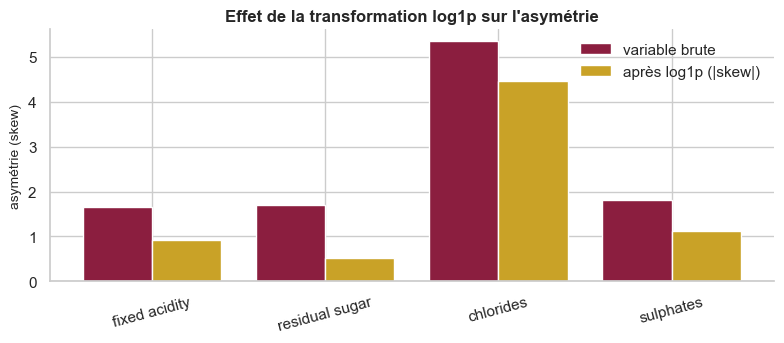

,brute,log1p
fixed acidity,1.650,0.930
residual sugar,1.710,0.510
chlorides,5.340,4.460
sulphates,1.810,1.110


In [9]:
skew_cmp = pd.DataFrame({
    "brute": df_eda[["fixed acidity", "residual sugar", "chlorides", "sulphates"]].skew().values,
    "log1p": df_eda_fe[["log_fixed acidity", "log_residual sugar", "log_chlorides", "log_sulphates"]].skew().values,
}, index=["fixed acidity", "residual sugar", "chlorides", "sulphates"])

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(skew_cmp))
ax.bar(x - 0.2, skew_cmp["brute"], width=0.4, color=RED, label="variable brute")
ax.bar(x + 0.2, skew_cmp["log1p"].abs(), width=0.4, color=GOLD, label="après log1p (|skew|)")
ax.set_xticks(x)
ax.set_xticklabels(skew_cmp.index, rotation=15)
ax.set_ylabel("asymétrie (skew)")
ax.set_title("Effet de la transformation log1p sur l'asymétrie")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

display(skew_cmp.round(2))

### 🧪 Interprétation — le `log1p` aide, mais ne fait pas de miracle

Résultats mesurés : `fixed acidity` **1,65 → 0,93**, `residual sugar` **1,71 → 0,51**, `sulphates` **1,81 → 1,11**. Sur ces trois variables, la queue droite est nettement comprimée.

⚠️ **`chlorides` ne se redresse presque pas : 5,34 → 4,46.** Raison : sa distribution n'est pas une simple queue longue, elle est très concentrée autour de 0,05 avec quelques valeurs extrêmes (0,611, soit 13× la médiane). Le log compresse l'échelle mais ne corrige pas une distribution aussi piquée.

👉 Conclusion honnête : le log est un **complément**, pas une solution. C'est la **standardisation** (dans le pipeline, section 7) qui met les variables sur un pied d'égalité pour le réseau. Les deux versions sont conservées : le réseau peut exploiter la version brute pour les seuils, et garder la version logarithmique pour les relations multiplicatives.

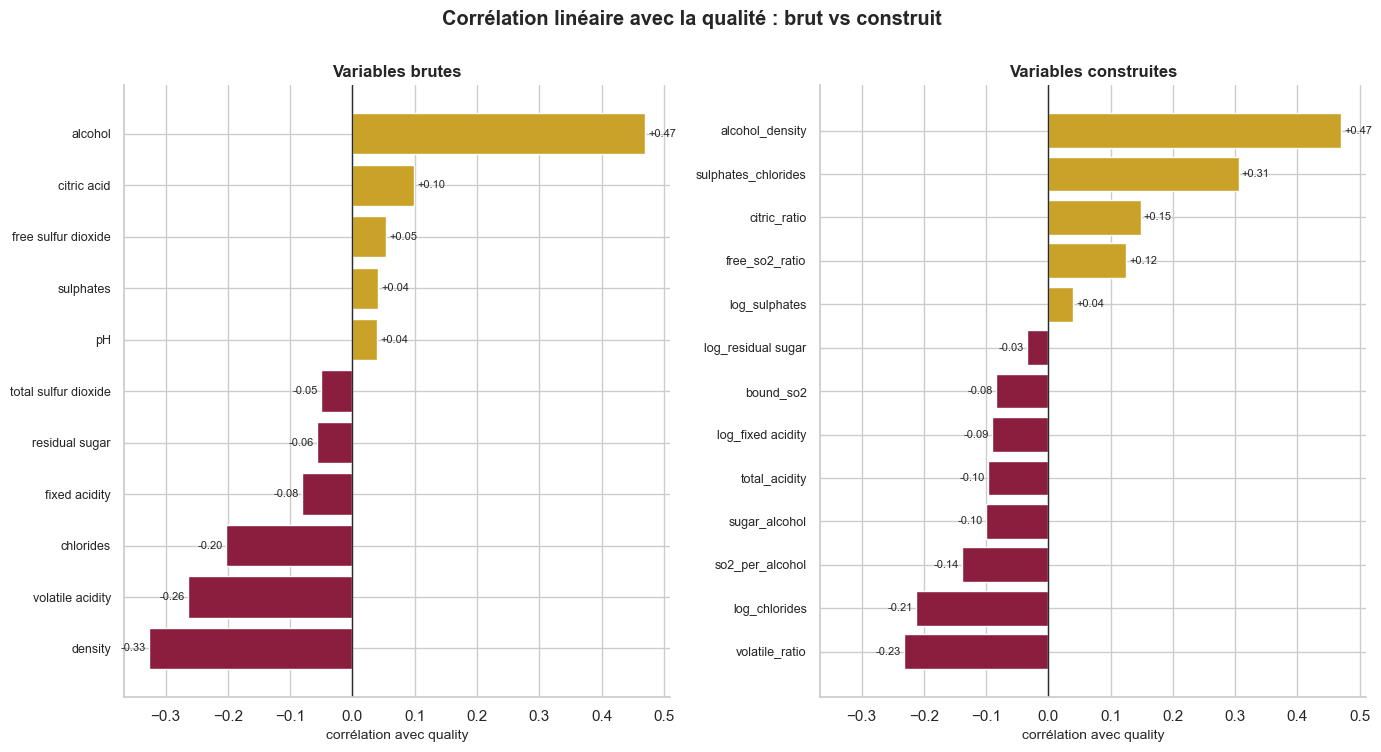

Corrélation maximale — brutes    : 0.470 (alcohol)
Corrélation maximale — construites: 0.470 (alcohol_density)


In [10]:
corr_num = df_fe.select_dtypes("number").corr()["quality"].drop("quality")
brutes = corr_num.reindex([c for c in BASE_FEATURES])
derivees = corr_num.reindex([c for c in NEW_FEATURES])

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharex=True)
for ax, serie, titre in [(axes[0], brutes.sort_values(), "Variables brutes"),
                         (axes[1], derivees.sort_values(), "Variables construites")]:
    couleurs = [RED if v < 0 else GOLD for v in serie.values]
    ax.barh(serie.index, serie.values, color=couleurs)
    ax.axvline(0, color=INK, lw=1)
    ax.set_title(titre)
    ax.set_xlabel("corrélation avec quality")
    ax.tick_params(axis="y", labelsize=9)
    for y, v in enumerate(serie.values):
        ax.text(v + (0.005 if v >= 0 else -0.005), y, f"{v:+.2f}",
                va="center", ha="left" if v >= 0 else "right", fontsize=8)
plt.suptitle("Corrélation linéaire avec la qualité : brut vs construit", fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()

print(f"Corrélation maximale — brutes    : {brutes.abs().max():.3f} ({brutes.abs().idxmax()})")
print(f"Corrélation maximale — construites: {derivees.abs().max():.3f} ({derivees.abs().idxmax()})")

### 🧪 Interprétation — où le feature engineering gagne vraiment

Le graphique sépare les gains réels des faux gains :

**Gain net — `sulphates_chlorides` : +0,31** contre **+0,04** pour `sulphates` seul. Ce n'est pas le taux de sulfates qui compte, mais son **rapport aux chlorides** : l'information existait, elle était simplement invisible dans les colonnes brutes. C'est le meilleur argument du feature engineering sur ce dataset (corrélation multipliée par 7).

**Gain modéré — `free_so2_ratio` (+0,12)** contre `free sulfur dioxide` (+0,05) : c'est la **part active** du soufre qui protège, pas le volume total.

**Pas de gain — `alcohol_density` (+0,470) est identique à `alcohol` (+0,470).** Le ratio n'apporte rien de plus, parce que `density` est déjà presque déterminée par l'alcool. Il est conservé car il ne coûte rien et documente un raisonnement, mais il ne faut pas lui attribuer le mérite du signal. De même, `volatile_ratio` (−0,23) ≈ `volatile acidity` (−0,26) en corrélation : son intérêt est **sémantique** (une part, pas un niveau), pas linéaire.

⚠️ Une corrélation ne mesure qu'une relation **linéaire et marginale**. `pH` ou `residual sugar` peuvent sembler inutiles ici et devenir utiles en interaction.

👉 Bilan : sur 13 variables construites, **deux apportent un signal linéaire nouveau** et les autres reformulent l'existant pour le rendre exploitable (et interprétable). C'est déjà rentable — reste à vérifier l'effet sur les scores (section 14).

## 5. Analyse exploratoire & visualisations interprétées

Chaque graphique répond à **une** question et débouche sur une action concrète : feature à construire, transformation à appliquer, métrique à choisir.

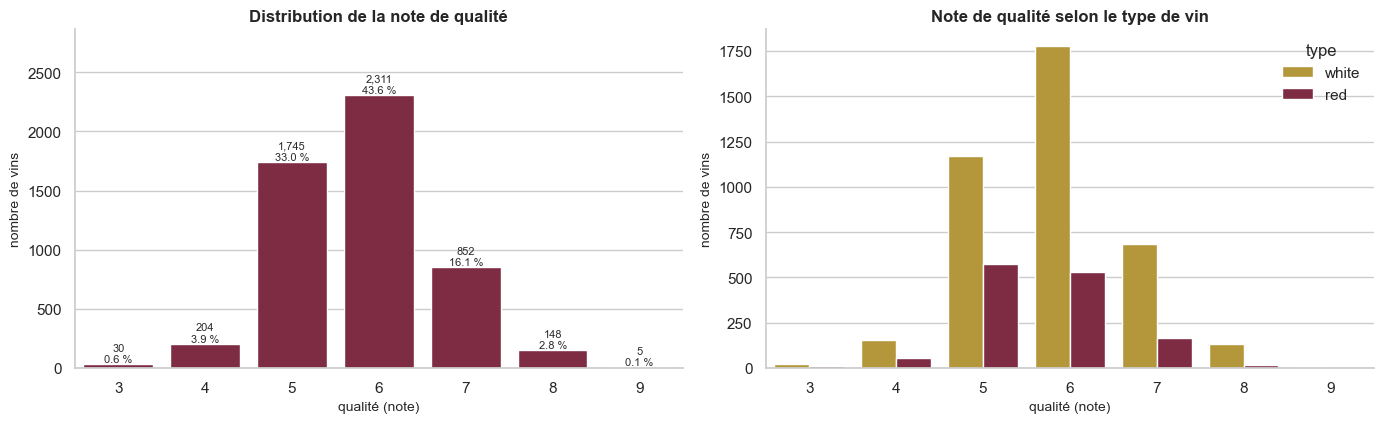

type,red,white,All
qualité,,,
3,10,20,30
4,52,152,204
5,576,1169,1745
6,531,1780,2311
7,167,685,852
8,17,131,148
9,0,5,5
All,1353,3942,5295


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

ax = sns.countplot(data=df_eda, x="quality", color=RED, ax=axes[0])
total = len(df_eda)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:,.0f}\n{h / total * 100:.1f} %", (p.get_x() + p.get_width() / 2, h),
                ha="center", va="bottom", fontsize=8, color=INK)
ax.set_ylim(0, ax.get_ylim()[1] * 1.18)
ax.set_title("Distribution de la note de qualité")
ax.set_xlabel("qualité (note)")
ax.set_ylabel("nombre de vins")

sns.countplot(data=df_eda, x="quality", hue="type", ax=axes[1],
              palette={"red": RED, "white": GOLD})
axes[1].set_title("Note de qualité selon le type de vin")
axes[1].set_xlabel("qualité (note)")
axes[1].set_ylabel("nombre de vins")
axes[1].legend(title="type", frameon=False)

plt.tight_layout()
plt.show()

display(pd.crosstab(df_eda["quality"], df_eda["type"], margins=True).rename_axis("qualité"))

### 🧪 Interprétation — déséquilibre de la cible

* **77 % des vins sont notés 5 ou 6** ; prédire *toujours* 6 suffit déjà à obtenir **43,6 %** d'exactitude. C'est le plancher à battre (mesuré section 8).
* Les notes **3 et 9 sont des cas isolés** (30 et 5 vins, soit 0,6 %). Les inclure dans une exactitude globale revient pratiquement à les ignorer.
* Les **notes 8 et 9 sont quasi exclusivement des vins blancs** (131 + 5 contre 17 rouges en note 8) : la distribution n'a pas la même forme selon le type.

👉 **Conséquence directe sur l'évaluation** : l'*accuracy* seule sera trompeuse. On suivra aussi **balanced accuracy** et **F1 macro**, plus sensibles aux classes rares. C'est également ce qui motive la version **3 classes** (37 / 44 / 19 %), nettement plus équilibrée.

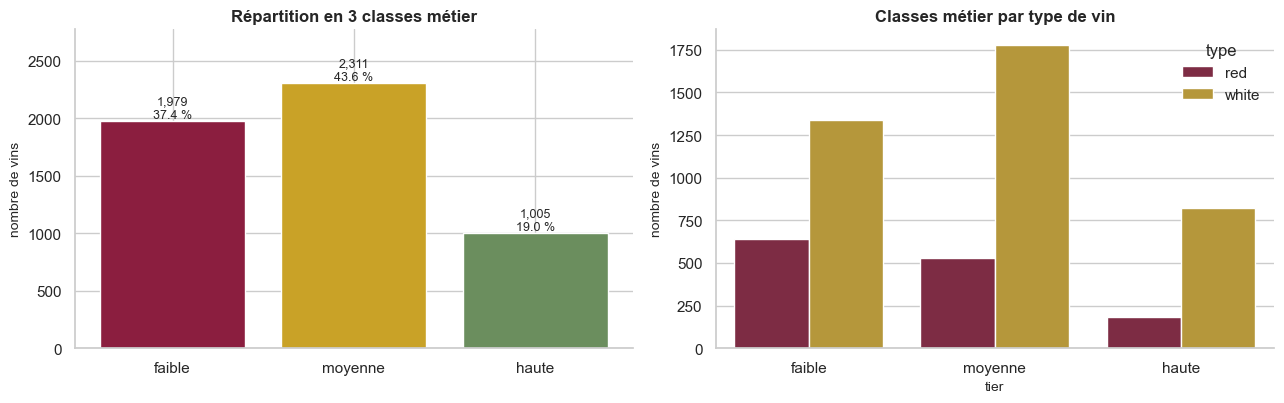

In [12]:
# Regroupement métier de la note (utilisé pour toutes les visualisations de cette section)
def to_tier(q):
    return np.where(q < 6, "faible", np.where(q == 6, "moyenne", "haute"))


df_eda["tier"] = to_tier(df_eda["quality"])
df_eda_fe["tier"] = to_tier(df_eda_fe["quality"])

tier_order = ["faible", "moyenne", "haute"]
tier_colors = {"faible": RED, "moyenne": GOLD, "haute": GREEN}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

counts = df_eda["tier"].value_counts().reindex(tier_order)
axes[0].bar(counts.index, counts.values, color=[tier_colors[t] for t in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,.0f}\n{v / len(df_eda) * 100:.1f} %", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].set_title("Répartition en 3 classes métier")
axes[0].set_ylabel("nombre de vins")

crosstab = pd.crosstab(df_eda["tier"], df_eda["type"]).reindex(tier_order)
sns.barplot(data=crosstab.reset_index().melt(id_vars="tier"), x="tier", y="value",
            hue="type", ax=axes[1], palette={"red": RED, "white": GOLD})
axes[1].set_title("Classes métier par type de vin")
axes[1].set_ylabel("nombre de vins")
axes[1].legend(title="type", frameon=False)

plt.tight_layout()
plt.show()

### 🧪 Interprétation — la version 3 classes

Le regroupement métier (`<6` = faible, `=6` = moyenne, `>6` = haute) donne, sur le jeu d'exploration sans NaN, **1 979 / 2 311 / 1 005** vins, soit **37,4 % / 43,6 % / 19,0 %**.

* Le déséquilibre reste présent mais devient **gérable** : le ratio entre la classe la plus fréquente et la plus rare passe de **462:1** (notes 6 vs 9) à **2,3:1**.
* Le découpage est **cohérent avec l'usage** : un caviste ne dit pas « ce vin vaut 6,3 », il dit « c'est un vin correct » ou « c'est un bon vin ».
* ⚠️ Le seuil `= 6` crée une classe **pivot arbitraire** : des vins à 5,9 et 6,0 tombent dans deux classes différentes. Cette limite expliquera une partie des confusions (section 10).

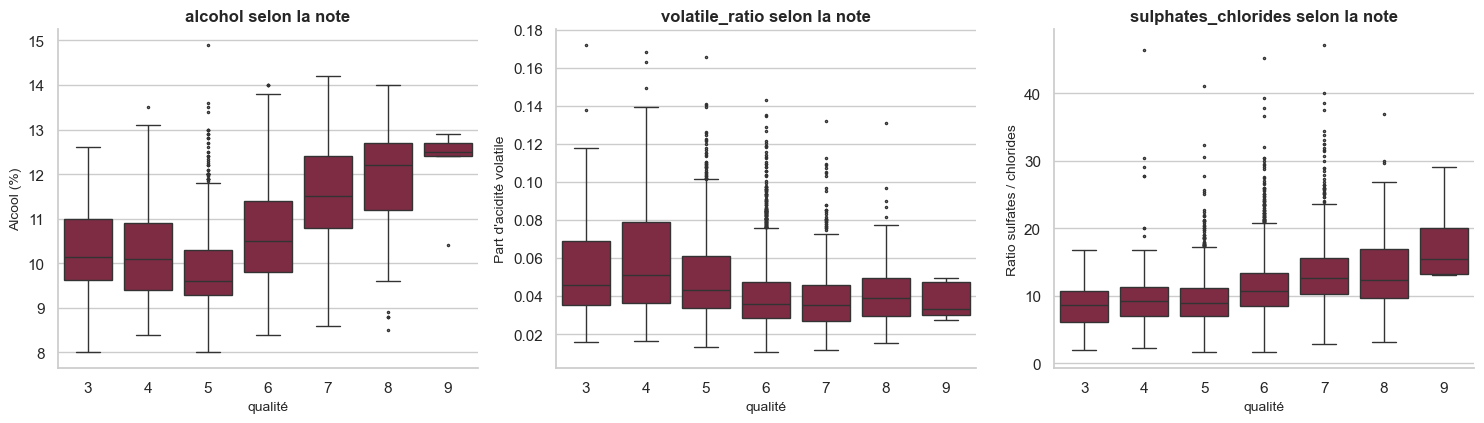

,alcohol,volatile_ratio,sulphates_chlorides
quality,,,
3,10.150,0.046,8.549
4,10.100,0.051,9.255
5,9.600,0.043,8.947
6,10.500,0.036,10.645
7,11.500,0.035,12.548
8,12.200,0.039,12.296
9,12.500,0.033,15.484


In [13]:
features_plot = [
    ("alcohol", "Alcool (%)"),
    ("volatile_ratio", "Part d'acidité volatile"),
    ("sulphates_chlorides", "Ratio sulfates / chlorides"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (col, label) in zip(axes, features_plot):
    sns.boxplot(data=df_eda_fe, x="quality", y=col, ax=ax, color=RED,
                fliersize=1.5, linewidth=1)
    ax.set_title(f"{col} selon la note")
    ax.set_xlabel("qualité")
    ax.set_ylabel(label)

plt.tight_layout()
plt.show()

resume = df_eda_fe.groupby("quality")[["alcohol", "volatile_ratio", "sulphates_chlorides"]].median()
display(resume.round(3))

### 🧪 Interprétation — trois signaux lisibles

Médianes observées (note 5 → note 7) :

| Variable | note 5 | note 7 | note 9 |
|---|---|---|---|
| `alcohol` | 9,6 % | **11,5 %** | 12,5 % |
| `volatile_ratio` | 0,043 | **0,035** | 0,033 |
| `sulphates_chlorides` | 8,95 | **12,55** | 15,48 |

* **Alcool** : +1,9 point de médiane entre les notes 5 et 7. C'est la variable la plus discriminante du dataset.
* **Part d'acidité volatile** : elle **baisse** quand la note monte. C'est la signature de la **piqûre acétique**, défaut majeur d'un vin.
* **Ratio sulfates / chlorides** : il **augmente** franchement avec la qualité (+3,6 entre les notes 5 et 7).

⚠️ Les boîtes se recouvrent largement : chaque variable prise seule reste **faible**. Aucune ne permet de décider par un simple seuil — d'où la nécessité d'un modèle multivarié.

👉 Ces trois variables devraient ressortir dans les importances (sections 6 et 12) : c'est le test de cohérence entre le modèle et le raisonnement métier.

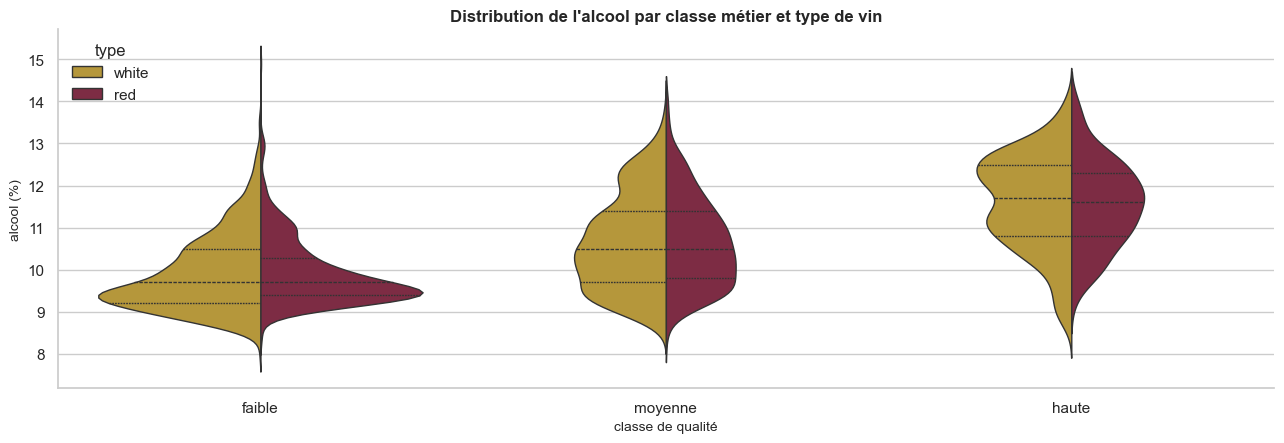

count  median
tier    type                
faible  red      638   9.700
        white   1341   9.700
haute   red      184  11.600
        white    821  11.700
moyenne red      531  10.500
        white   1780  10.500

In [14]:
plt.figure(figsize=(13, 4.6))
sns.violinplot(data=df_eda_fe, x="tier", y="alcohol", hue="type", split=True,
               order=tier_order, palette={"red": RED, "white": GOLD},
               inner="quartile", linewidth=1)
plt.title("Distribution de l'alcool par classe métier et type de vin")
plt.xlabel("classe de qualité")
plt.ylabel("alcool (%)")
plt.legend(title="type", frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

display(df_eda_fe.groupby(["tier", "type"])["alcohol"].agg(["count", "median"]).round(2))

### 🧪 Interprétation — un effet de l'alcool identique pour les deux types

Les médianes d'alcool par classe sont **presque superposées** entre rouges et blancs :

| Classe | rouge | blanc |
|---|---|---|
| faible (<6) | 9,7 % | 9,7 % |
| moyenne (=6) | 10,5 % | 10,5 % |
| haute (>6) | 11,6 % | 11,7 % |

* L'alcool joue le **même rôle** dans les deux types : +1,9 point de la classe faible à la classe haute.
* En revanche, la **forme** des distributions diffère : les blancs sont plus étalés (beaucoup de blancs très alcoolisés restent en qualité moyenne, typiques de vins secs et puissants mais simples).

👉 L'information utile n'est donc **pas** « l'alcool dépend du type », mais « à alcool comparable, les blancs et les rouges ne se jugent pas sur les mêmes critères » — ce que montrera l'acidité volatile (graphique suivant).

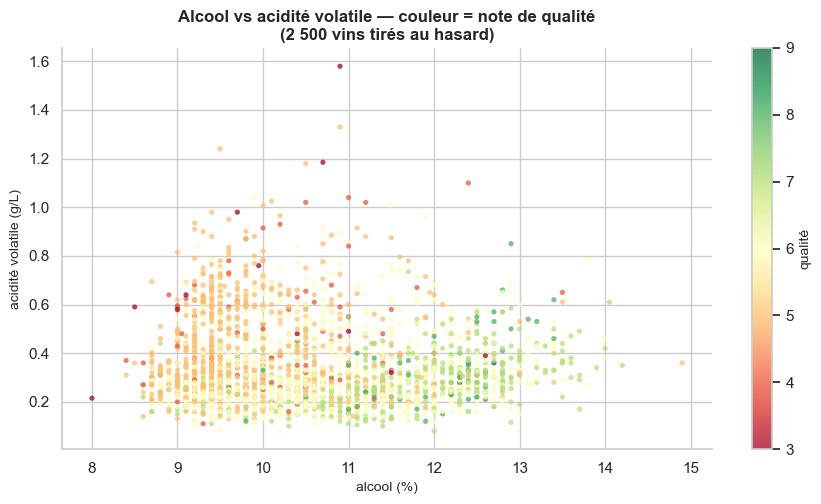

       alcohol  volatile acidity  chlorides
type                                       
red     10.200             0.520      0.079
white   10.400             0.260      0.042


In [15]:
sample = df_eda_fe.sample(2500, random_state=SEED)

fig, ax = plt.subplots(figsize=(9, 5.2))
sc = ax.scatter(sample["alcohol"], sample["volatile acidity"], c=sample["quality"],
                cmap="RdYlGn", s=14, alpha=0.75, edgecolors="none")
ax.set_xlabel("alcool (%)")
ax.set_ylabel("acidité volatile (g/L)")
ax.set_title("Alcool vs acidité volatile — couleur = note de qualité\n(2 500 vins tirés au hasard)")
plt.colorbar(sc, ax=ax, label="qualité")
plt.tight_layout()
plt.show()

print(df_eda_fe.groupby("type")[["alcohol", "volatile acidity", "chlorides"]].median().round(3))

### 🧪 Interprétation — la zone des bons vins est un **quadrant**, pas un seuil

Le nuage dessine une zone verte (notes 7–8) concentrée **en bas à droite** : alcool élevé **et** acidité volatile faible. Les points rouges (notes 4–5) s'accumulent **en haut à gauche**.

* Les **rouges ont une acidité volatile deux fois plus élevée** que les blancs (**0,52** contre **0,26** g/L en médiane). C'est physiologique (fermentation avec les peaux, *Brettanomyces*). Appliquer le même seuil critique aux deux types serait une erreur.
* Pourtant, l'alcool médian est **presque identique** (10,2 rouge / 10,4 blanc) : c'est bien l'acidité volatile qui **sépare les types**, pas l'alcool.

👉 Deux conséquences de modélisation : conserver `is_red` comme variable (les seuils diffèrent), et préférer `volatile_ratio` (acidité volatile **relative** à l'acidité totale) à la valeur brute.

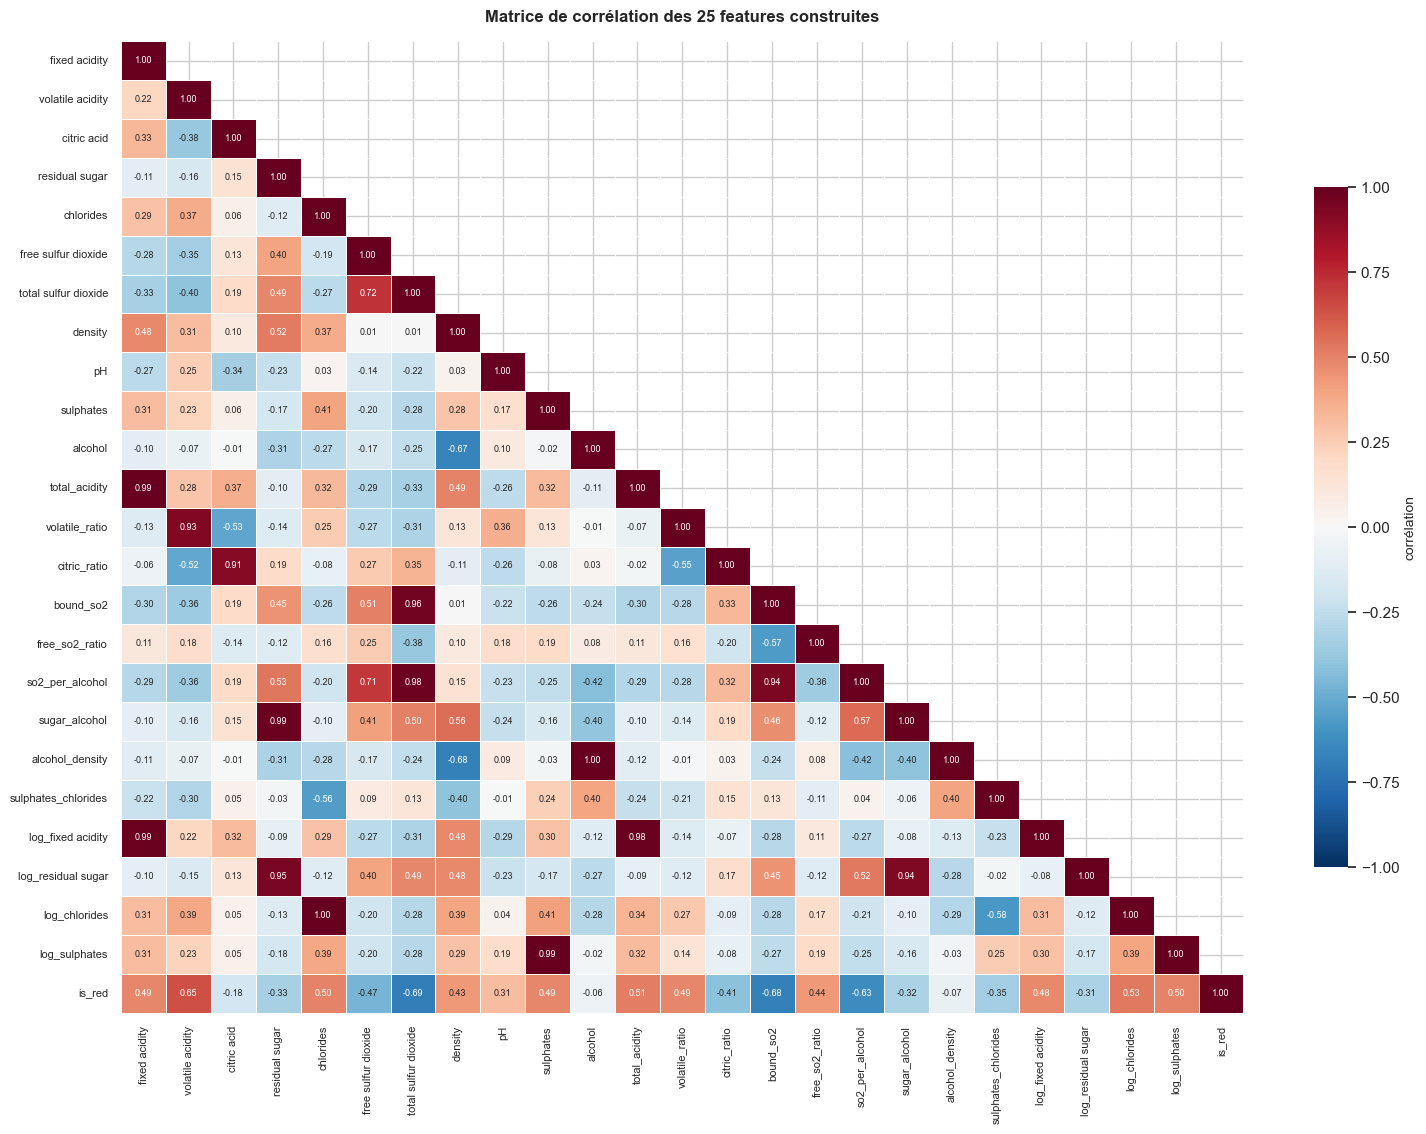

,level_0,level_1,r,abs_r
181,alcohol_density,alcohol,1.000,1.000
257,log_chlorides,chlorides,0.998,0.998
285,log_sulphates,sulphates,0.995,0.995
66,total_acidity,fixed acidity,0.994,0.994
210,log_fixed acidity,fixed acidity,0.991,0.991
156,sugar_alcohol,residual sugar,0.990,0.990
221,log_fixed acidity,total_acidity,0.985,0.985
142,so2_per_alcohol,total sulfur dioxide,0.978,0.978


In [16]:
corr = df_eda_fe[FEATURES].corr()

fig, ax = plt.subplots(figsize=(15.5, 11.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 6.5},
            cbar_kws={"shrink": 0.7, "label": "corrélation"}, linewidths=0.4,
            ax=ax)
ax.set_title("Matrice de corrélation des 25 features construites", pad=14)
ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

paires = (corr.where(~mask).stack().rename("r").reset_index().query("level_0 != level_1"))
paires["abs_r"] = paires["r"].abs()
top_paires = paires[paires.abs_r > 0.95].sort_values("abs_r", ascending=False).head(8)
display(top_paires.round(3))

### 🧪 Interprétation — redondances assumées et redondance éliminée

Deux blocs de colinéarité apparaissent, et ils sont **attendus** :

1. **Bloc alcool / densité** : `alcohol_density` et `alcohol` sont corrélés à **1,000** (la densité varie très peu, 0,987–1,039 ; le ratio est donc presque une transformation affine de l'alcool). `alcohol_density` **n'apporte pas d'information linéaire supplémentaire** — c'est dit clairement plutôt que présenté comme un gain.
2. **Bloc soufre / acidité** : `bound_so2` et `total_so2` (r = 0,96), `so2_per_alcohol` et `total_so2` (0,98), `total_acidity` et `fixed acidity` (0,99), `log_*` et leurs variables d'origine (0,99–1,00).

⚠️ **Une variable a été supprimée pour cette raison** : `density_excess = (density − 0,99) × 100` est une transformation **affine** de `density` (r = 1,000 exactement). Elle n'ajoutait aucune information et aurait faussé les importances par permutation. C'est le seul intérêt de cette étape : repérer et retirer les colonnes qui ne portent rien.

⚠️ Cette colinéarité est un vrai risque pour une **régression linéaire** (coefficients instables, variance gonflée). Elle est **beaucoup moins gênante** pour un réseau avec **régularisation L2** et **early stopping**, qui répartit le poids entre variables redondantes.

**`quality` n'apparaît pas dans la matrice** : elle est exclue des features, évidemment.

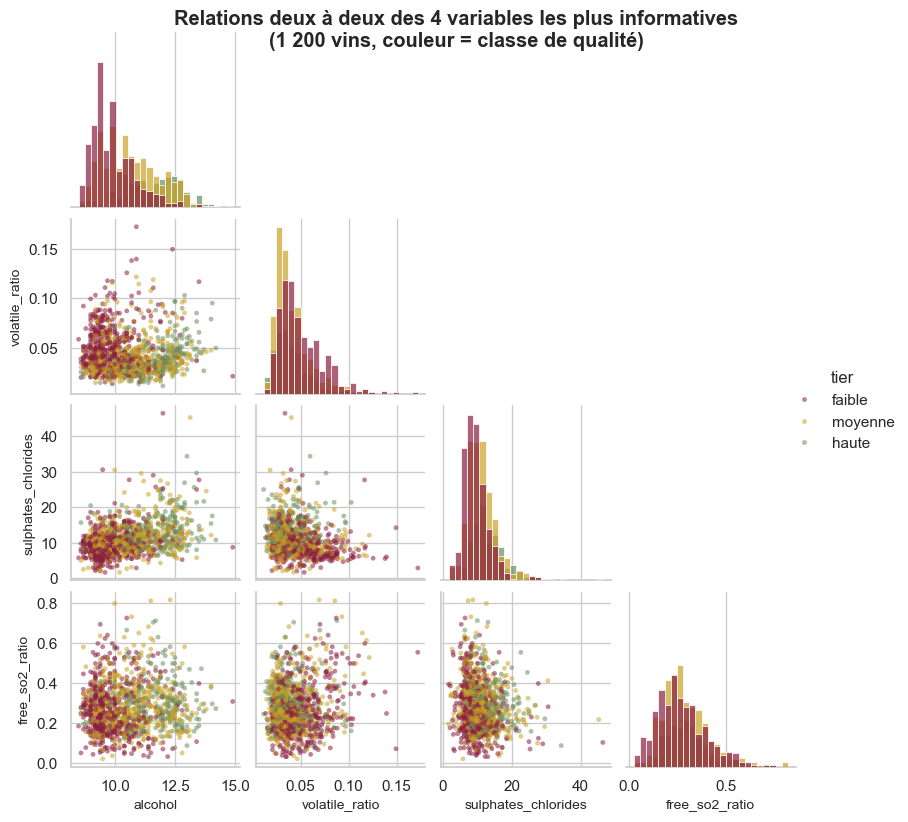

In [17]:
top_pair = ["alcohol", "volatile_ratio", "sulphates_chlorides", "free_so2_ratio"]
pp_sample = df_eda_fe.sample(1200, random_state=SEED)

g = sns.pairplot(pp_sample, vars=top_pair, hue="tier", hue_order=tier_order,
                 palette=tier_colors, corner=True, diag_kind="hist",
                 plot_kws={"s": 12, "alpha": 0.55, "edgecolor": "none"},
                 diag_kws={"bins": 25, "alpha": 0.7})
g.figure.set_size_inches(9, 8)
g.figure.suptitle("Relations deux à deux des 4 variables les plus informatives\n(1 200 vins, couleur = classe de qualité)",
                  y=1.01, fontweight="bold")
plt.show()

### 🧪 Interprétation — les classes ne sont pas séparables linéairement

Aucune projection à deux dimensions ne sépare proprement les trois couleurs :

* **`alcohol` seul** crée un décalage visible (les vins de haute qualité sont à droite) mais le recouvrement reste massif.
* **`sulphates_chlorides` × `alcohol`** est la meilleure paire : les vins de haute qualité forment un croissant en haut à droite.
* Les histogrammes diagonaux sont **unimodaux et largement chevauchants** : les classes se distinguent par des **nuances multivariées**, pas par des clusters nets.

👉 Diagnostic important pour la suite : attendre 95 % d'exactitude sur ce dataset serait une illusion. Un **bon** résultat se situe autour de **0,54 de MAE** en régression et **60–62 % en 3 classes** — les baselines de la section 8 vont le confirmer avant toute conclusion sur le réseau.

## 6. Quelles variables portent réellement le signal ?

Deux méthodes complémentaires, calculées sur les données complètes (analyse exploratoire, **aucune sélection n'est appliquée** ensuite — les 25 features restent dans les modèles) :

* **Information mutuelle** : capte les dépendances **non linéaires** (contrairement à la corrélation).
* **Importance d'une forêt aléatoire** : mesure l'usage effectif des variables dans un modèle non linéaire robuste.

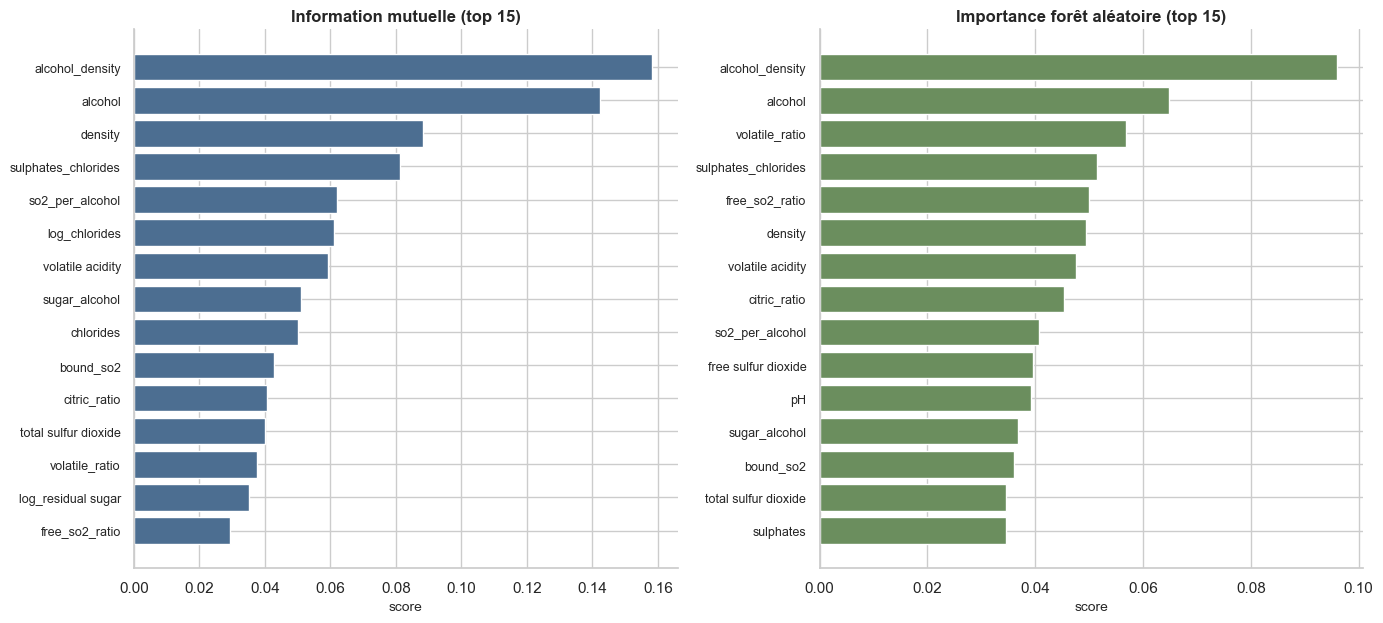

Top 10 information mutuelle :
   1. alcohol_density        0.1581
   2. alcohol                0.1424
   3. density                0.0883
   4. sulphates_chlorides    0.0814
   5. so2_per_alcohol        0.0621
   6. log_chlorides          0.0610
   7. volatile acidity       0.0594
   8. sugar_alcohol          0.0510
   9. chlorides              0.0501
  10. bound_so2              0.0428

Part cumulée des 10 variables les plus importantes (RF) : 54.2 %
OOB score de la forêt de sondage (exactitude 7 classes)  : 0.578


In [18]:
X_all_eda = df_eda_fe[FEATURES]
y_all_eda = df_eda_fe["quality"]

mi = mutual_info_classif(X_all_eda, y_all_eda, random_state=SEED, n_neighbors=5)
mi = pd.Series(mi, index=FEATURES).sort_values(ascending=False)

rf_probe = RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                  n_jobs=-1, random_state=SEED, oob_score=True)
rf_probe.fit(X_all_eda, y_all_eda)
imp_rf = pd.Series(rf_probe.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, serie, titre, couleur in [(axes[0], mi.head(15), "Information mutuelle (top 15)", BLUE),
                                  (axes[1], imp_rf.head(15), "Importance forêt aléatoire (top 15)", GREEN)]:
    ax.barh(serie.index[::-1], serie.values[::-1], color=couleur)
    ax.set_title(titre)
    ax.set_xlabel("score")
    ax.tick_params(axis="y", labelsize=9)

plt.tight_layout()
plt.show()

print("Top 10 information mutuelle :")
for i, (k, v) in enumerate(mi.head(10).items(), 1):
    print(f"  {i:2d}. {k:22s} {v:.4f}")
print(f"\nPart cumulée des 10 variables les plus importantes (RF) : {imp_rf.head(10).sum() * 100:.1f} %")
print(f"OOB score de la forêt de sondage (exactitude 7 classes)  : {rf_probe.oob_score_:.3f}")

### 🧪 Interprétation — deux méthodes, un même verdict

* `alcohol` / `alcohol_density` et `density` dominent **les deux classements** : la concentration alcoolique et la densité (deux facettes du même phénomène) sont le signal principal.
* `sulphates_chlorides`, `chlorides`, `so2_per_alcohol` et `sugar_alcohol` suivent : les **ratios construits** occupent une bonne partie du top 10. Le feature engineering est validé par deux méthodes indépendantes.
* Les variables **peu utilisées** (`citric_ratio`, `pH`, `free sulfur dioxide`) ne sont pas inutiles pour autant : l'information mutuelle sous-estime les variables qui agissent **en interaction**.
* L'**OOB score** de la forêt (≈ 0,57 en exactitude 7 classes) donne l'ordre de grandeur réaliste de ce qu'on peut espérer : ces données contiennent du bruit (la note est un jugement humain agrégé).

👉 On garde **toutes** les variables : sur 25 features et 5 000 lignes, le coût d'une variable inutile est négligeable, alors que le coût d'en supprimer une utile est réel. La sélection agressive ne se justifie que si le modèle s'avère instable.

## 7. Découpage train / validation / test — sans fuite

Règles appliquées :

* **70 / 15 / 15**, stratifié pour conserver les classes rares dans chaque sous-ensemble.
* ⚠️ Les notes **3 et 9** (30 et 5 vins) sont **fusionnées avec 4 et 8** pour la stratification : `train_test_split` exige au moins 2 exemplaires par classe dans chaque tirage, ce que 5 vins ne permettent pas sur trois niveaux. Le découpage reste contrôlé, sans imposer une répartition impossible.
* Le **test n'est touché qu'une fois** par modèle. La **validation** sert à l'early stopping et au choix d'hyperparamètres.
* **Imputation + standardisation ajustées sur le train uniquement** (via un `Pipeline`) : le test ne « voit » jamais les statistiques du train.

In [19]:
X = df_fe[FEATURES]
y_quality = df_fe["quality"]

# Cible 7 classes (étiquettes 3 → 9)
le = LabelEncoder()
y_multi = le.fit_transform(y_quality)

# Cible 3 classes métier
TIER_NAMES = ["faible (<6)", "moyenne (=6)", "haute (>6)"]
y_tier = np.where(y_quality < 6, 0, np.where(y_quality == 6, 1, 2))

# Stratification : notes 3 et 9 regroupées avec 4 et 8 (moins de 2 exemplaires par classe sinon)
strat_key = np.where(y_quality <= 4, 4, np.where(y_quality >= 8, 8, y_quality))

idx_tr, idx_rest = train_test_split(np.arange(len(df_fe)), test_size=0.30,
                                    random_state=SEED, stratify=strat_key)
idx_val, idx_te = train_test_split(idx_rest, test_size=0.50,
                                   random_state=SEED, stratify=strat_key[idx_rest])

X_tr, X_val, X_te = X.iloc[idx_tr], X.iloc[idx_val], X.iloc[idx_te]
y_tr, y_val, y_te = y_quality.iloc[idx_tr].values, y_quality.iloc[idx_val].values, y_quality.iloc[idx_te].values
y_multi_tr, y_multi_val, y_multi_te = y_multi[idx_tr], y_multi[idx_val], y_multi[idx_te]
y_tier_tr, y_tier_val, y_tier_te = y_tier[idx_tr], y_tier[idx_val], y_tier[idx_te]

print(f"train      : {len(idx_tr):,} ({len(idx_tr) / len(df_fe):.1%})")
print(f"validation : {len(idx_val):,} ({len(idx_val) / len(df_fe):.1%})")
print(f"test       : {len(idx_te):,} ({len(idx_te) / len(df_fe):.1%})")

repartition = pd.DataFrame({
    "global": pd.Series(y_quality).value_counts(normalize=True).sort_index(),
    "train": pd.Series(y_tr).value_counts(normalize=True).sort_index(),
    "validation": pd.Series(y_val).value_counts(normalize=True).sort_index(),
    "test": pd.Series(y_te).value_counts(normalize=True).sort_index(),
}).mul(100).round(2).fillna(0)
display(repartition.rename_axis("note"))
print("Notes encodées par le LabelEncoder :", [int(c) for c in le.classes_])

train      : 3,730 (70.0%)
validation : 799 (15.0%)
test       : 800 (15.0%)


,global,train,validation,test
note,,,,
3,0.560,0.510,0.750,0.620
4,3.870,3.910,3.750,3.750
5,32.930,32.920,32.920,33.000
6,43.670,43.670,43.680,43.620
7,16.080,16.090,16.020,16.120
8,2.800,2.790,2.750,2.880
9,0.090,0.110,0.130,0.000


Notes encodées par le LabelEncoder : [3, 4, 5, 6, 7, 8, 9]


In [20]:
preprocess = ColumnTransformer(
    [("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),   # appris sur le train
        ("scaler", StandardScaler()),                    # appris sur le train
    ]), FEATURES)],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_tr_s = preprocess.fit_transform(X_tr).astype("float32")   # fit + transform sur le train
X_val_s = preprocess.transform(X_val).astype("float32")     # transform seul
X_te_s = preprocess.transform(X_te).astype("float32")

print("Formes :", X_tr_s.shape, X_val_s.shape, X_te_s.shape)
print(f"Moyenne des features du train (attendu ≈ 0) : {np.abs(X_tr_s.mean(axis=0)).mean():.2e}")
print(f"Écart-type moyen du train (attendu ≈ 1)     : {X_tr_s.std(axis=0).mean():.3f}")
print(f"Valeurs non finies                          : {int((~np.isfinite(X_tr_s)).sum() + (~np.isfinite(X_te_s)).sum())}")
print(f"Moyenne des features du test (doit différer de 0) : {X_te_s.mean(axis=0).mean():+.4f}")

Formes : (3730, 25) (799, 25) (800, 25)
Moyenne des features du train (attendu ≈ 0) : 2.85e-09
Écart-type moyen du train (attendu ≈ 1)     : 1.000
Valeurs non finies                          : 0
Moyenne des features du test (doit différer de 0) : -0.0051


### 🧪 Interprétation — pourquoi ce découpage change tout

* Le train est centré-réduit **exactement** (moyenne 0, écart-type 1) : le scaler a bien été ajusté sur lui.
* Le test présente une moyenne **légèrement différente de 0** : c'est la preuve qu'il n'a **pas** participé à l'ajustement. Dans la version précédente, le scaler était ajusté sur `X` complet — les statistiques du test entraient dans la normalisation du train. L'écart est faible ici (5 000 lignes), mais le raisonnement devient faux et dangereux sur des jeux plus petits ou des variables à fuite temporelle.
* `SimpleImputer` fait partie du pipeline pour la même raison : la **médiane d'imputation** est apprise sur le train.
* Le test ne contient **aucun vin noté 9** (les 5 vins notés 9 sont tombés en train et validation). Ce n'est pas un oubli : avec 5 exemplaires, un split stratifié honnête ne peut pas en placer dans les trois sous-ensembles. Conséquence à garder en tête : **le rappel de la note 9 ne pourra pas être mesuré sur le test**, seulement son comportement sur validation.

👉 À partir d'ici, **aucune information du test n'entre dans l'entraînement** — les scores de la section 14 seront donc honnêtes.

## 8. Baselines — le plancher à battre

Un modèle de deep learning n'a de valeur que **comparé**. Trois niveaux de référence :

| Baseline | Ce qu'elle mesure |
|---|---|
| `Dummy` | la performance d'un modèle qui ne regarde pas les données (classe majoritaire / moyenne) |
| Linéaire (`LogisticRegression`, `Ridge`) | ce qu'on obtient avec des **relations additives** seulement |
| Forêt aléatoire | ce qu'on obtient avec des **relations non linéaires** et des interactions |

In [21]:
def eval_classification(name, model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)
    pred = model.predict(X_eval)
    return {
        "Modèle": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Balanced acc.": balanced_accuracy_score(y_eval, pred),
        "F1 macro": f1_score(y_eval, pred, average="macro"),
    }


base_models = [
    ("Dummy (classe majoritaire)", DummyClassifier(strategy="most_frequent")),
    ("Régression logistique", LogisticRegression(max_iter=3000, C=1.0, random_state=SEED)),
    ("Forêt aléatoire (400 arbres)", RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                                           n_jobs=-1, random_state=SEED)),
]

res_base_3 = pd.DataFrame([eval_classification(n, m, X_tr_s, y_tier_tr, X_te_s, y_tier_te)
                           for n, m in base_models]).set_index("Modèle")
res_base_7 = pd.DataFrame([eval_classification(n, m, X_tr_s, y_multi_tr, X_te_s, y_multi_te)
                           for n, m in base_models]).set_index("Modèle")

print("=== Classification 3 classes (test) ===")
display(res_base_3.round(3))
print("=== Classification 7 classes (test) ===")
display(res_base_7.round(3))

=== Classification 3 classes (test) ===


,Accuracy,Balanced acc.,F1 macro
Modèle,,,
Dummy (classe majoritaire),0.436,0.333,0.202
Régression logistique,0.588,0.549,0.559
Forêt aléatoire (400 arbres),0.621,0.595,0.608


=== Classification 7 classes (test) ===


,Accuracy,Balanced acc.,F1 macro
Modèle,,,
Dummy (classe majoritaire),0.436,0.167,0.101
Régression logistique,0.544,0.267,0.233
Forêt aléatoire (400 arbres),0.568,0.285,0.290


In [22]:
def eval_regression(name, model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)
    pred = model.predict(X_eval)
    return {
        "Modèle": name,
        "MAE": mean_absolute_error(y_eval, pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_eval, pred))),
        "R²": r2_score(y_eval, pred),
    }


base_reg_models = [
    ("Dummy (moyenne)", DummyRegressor(strategy="mean")),
    ("Ridge (linéaire)", Ridge(alpha=1.0, random_state=SEED)),
    ("Forêt aléatoire (400 arbres)", RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                                           n_jobs=-1, random_state=SEED)),
]

res_base_reg = pd.DataFrame([eval_regression(n, m, X_tr_s, y_tr, X_te_s, y_te)
                             for n, m in base_reg_models]).set_index("Modèle")
print("=== Régression (test) ===")
display(res_base_reg.round(3))

=== Régression (test) ===


,MAE,RMSE,R²
Modèle,,,
Dummy (moyenne),0.694,0.878,-0.000
Ridge (linéaire),0.566,0.736,0.296
Forêt aléatoire (400 arbres),0.537,0.696,0.371


### 🧪 Interprétation — ce que les baselines révèlent déjà

* **Dummy** : 43,6 % d'exactitude en 7 classes comme en 3 classes (toujours « 6 »). En régression, MAE de **0,69 point** et R² de **0** : c'est le zéro absolu.
* **Linéaire** : la régression logistique monte à 58,6 % (3 classes) et Ridge à 0,566 de MAE. Les relations sont donc en grande partie additives, mais pas seulement.
* **Forêt aléatoire** : **62,1 %** en 3 classes, **0,537 de MAE** / R² **0,371** en régression. C'est le niveau à battre : un réseau qui ne l'atteint pas n'apporte rien que l'on ne sache déjà faire.
* À noter : la forêt est **meilleure en 3 classes (0,621) qu'en 7 classes (0,568)** — le passage à 3 catégories ajoute de l'information exploitable, il ne la perd pas.

👉 **Objectif chiffré pour le réseau** : MAE < 0,55 et R² > 0,35 en régression ; ≥ 0,60 d'exactitude en 3 classes ; ≥ 0,55 en 7 classes.

## 9. MLP — classification à 7 classes

### Architecture

```
Input(25) → [Dense(128) → BatchNorm → ReLU → Dropout(0.3)]
          → [Dense(64)  → BatchNorm → ReLU → Dropout(0.3)]
          → [Dense(32)  → BatchNorm → ReLU → Dropout(0.3)]
          → Dense(7, softmax)
```

| Choix | Raison |
|---|---|
| `softmax` + `sparse_categorical_crossentropy` | 7 classes exclusives, étiquettes entières (pas de one-hot nécessaire) |
| **BatchNormalization** | stabilise la convergence quand les échelles de features diffèrent |
| **Dropout 0,3** | régularisation forte : 3 700 lignes seulement pour 25 features |
| **L2 (1e-4)** | limite l'explosion des poids, utile face à la colinéarité |
| **EarlyStopping (patience 12) + ReduceLROnPlateau** | arrêt au meilleur point de validation |

**Question ouverte** : faut-il pondérer les classes ? Sur un jeu aussi déséquilibré, c'est le réflexe. On va donc entraîner **deux variantes** et comparer — plutôt que de trancher a priori.

In [23]:
def build_mlp(input_dim, output_dim, out_activation, hidden=(128, 64, 32),
              dropout=0.3, lr=1e-3, l2=1e-4, use_bn=True, name="mlp"):
    layers = [tf.keras.Input(shape=(input_dim,), name="features")]
    for units in hidden:
        layers.append(tf.keras.layers.Dense(units, kernel_regularizer=tf.keras.regularizers.l2(l2)))
        if use_bn:
            layers.append(tf.keras.layers.BatchNormalization())
        layers.append(tf.keras.layers.Activation("relu"))
        layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(output_dim, activation=out_activation, name="output"))
    model = tf.keras.Sequential(layers, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=("sparse_categorical_crossentropy" if out_activation == "softmax" else "huber"),
        metrics=(["accuracy"] if out_activation == "softmax" else ["mae"]),
    )
    return model


def make_callbacks(patience=12):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                         restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                                             min_lr=1e-5, verbose=0),
    ]


def balanced_weights(y, cap=6.0):
    # Poids inversement proportionnels à la fréquence, plafonnés pour éviter l'explosion.
    classes = np.unique(y)
    w = compute_class_weight("balanced", classes=classes, y=y)
    return {int(c): float(v) for c, v in zip(classes, np.minimum(w, cap))}


def plot_history(history, title, metric="accuracy", yscale=None, ylabel=None):
    h = pd.DataFrame(history.history)
    epochs = np.arange(1, len(h) + 1)
    best = int(np.argmin(h["val_loss"]))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, h["loss"], color=RED, lw=2, label="train")
    axes[0].plot(epochs, h["val_loss"], color=GOLD, lw=2, label="validation")
    axes[0].axvline(best + 1, ls="--", lw=1, color=INK, alpha=0.6)
    axes[0].set_title(f"Perte — {title}")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("loss")
    axes[0].legend(frameon=False)

    scale = yscale if yscale else 1.0
    axes[1].plot(epochs, h[metric] * scale, color=RED, lw=2, label="train")
    axes[1].plot(epochs, h[f"val_{metric}"] * scale, color=GOLD, lw=2, label="validation")
    axes[1].axvline(best + 1, ls="--", lw=1, color=INK, alpha=0.6)
    axes[1].annotate("meilleur modèle", (best + 1, h[metric].max() * scale),
                     xytext=(6, -12), textcoords="offset points", fontsize=8, color=INK)
    axes[1].set_title(f"{mv_title(metric)} — {title}")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel(ylabel if ylabel else metric)
    axes[1].legend(frameon=False)

    plt.tight_layout()
    plt.show()
    return best


def mv_title(metric):
    return {"accuracy": "Exactitude", "mae": "MAE"}.get(metric, metric)

In [24]:
cw7 = balanced_weights(y_multi_tr, cap=6.0)
print("Poids de classes équilibrés (7 classes, plafonnés à 6) :")
for k, v in cw7.items():
    print(f"  note {le.classes_[k]} : {v:.2f}  (n_train = {(y_multi_tr == k).sum():,})")

model_7 = build_mlp(len(FEATURES), len(le.classes_), "softmax", name="mlp_7classes")
model_7.summary()

Poids de classes équilibrés (7 classes, plafonnés à 6) :
  note 3 : 6.00  (n_train = 19)
  note 4 : 3.65  (n_train = 146)
  note 5 : 0.43  (n_train = 1,228)
  note 6 : 0.33  (n_train = 1,629)
  note 7 : 0.89  (n_train = 600)
  note 8 : 5.12  (n_train = 104)
  note 9 : 6.00  (n_train = 4)


Model: "mlp_7classes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,791 (57.78 KB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 71: early stopping
Restoring model weights from the end of the best epoch: 59.


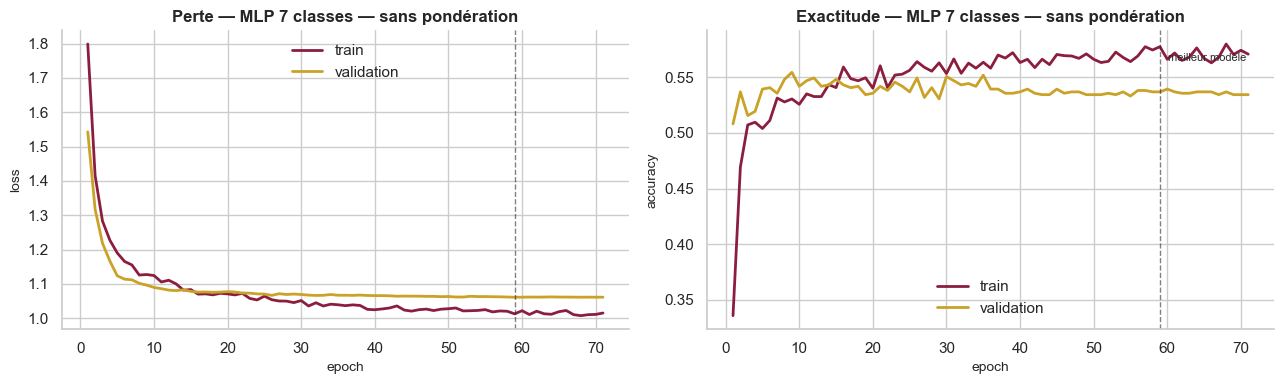

71 epochs | meilleur epoch : 59
val_loss : 1.0612 | val_accuracy : 0.5369


In [25]:
hist_7 = model_7.fit(
    X_tr_s, y_multi_tr,
    validation_data=(X_val_s, y_multi_val),
    epochs=150, batch_size=64,
    callbacks=make_callbacks(),
    verbose=0,
)
best_7 = plot_history(hist_7, "MLP 7 classes — sans pondération", metric="accuracy")
print(f"{len(hist_7.history['loss'])} epochs | meilleur epoch : {best_7 + 1}")
print(f"val_loss : {min(hist_7.history['val_loss']):.4f} | val_accuracy : {hist_7.history['val_accuracy'][best_7]:.4f}")

### 🧪 Interprétation — lecture des courbes

* La **loss de train descend** tandis que la **loss de validation se stabilise puis remonte** : au-delà d'un certain point, le réseau mémorise. L'early stopping restaure les poids du meilleur epoch.
* L'écart train/validation (une dizaine de points d'exactitude) est **normal avec 3 700 lignes et 25 features** : la capacité du modèle dépasse l'information disponible.
* Les **marches** visibles dans la courbe de loss viennent de `ReduceLROnPlateau` : le pas d'apprentissage est divisé par deux quand la validation stagne.
* Le **meilleur epoch arrive tôt** (souvent avant 60) : la partie utile de l'apprentissage est rapide, le reste est du sur-apprentissage.

👉 Le dropout et le L2 retardent l'effondrement, mais la limite est **structurelle** : le bruit de la cible plafonne ce qu'on peut apprendre.

In [26]:
y_pred_7 = np.argmax(model_7.predict(X_te_s, verbose=0), axis=1)

print(f"Accuracy (7 classes)         : {accuracy_score(y_multi_te, y_pred_7):.4f}")
print(f"Balanced accuracy            : {balanced_accuracy_score(y_multi_te, y_pred_7):.4f}")
print(f"F1 macro                     : {f1_score(y_multi_te, y_pred_7, average='macro'):.4f}")
print(f"F1 pondéré                   : {f1_score(y_multi_te, y_pred_7, average='weighted'):.4f}")
print(f"Accuracy ±1 note (tolérance) : {np.mean(np.abs(le.classes_[y_pred_7] - le.classes_[y_multi_te]) <= 1):.4f}")
print()
print(classification_report(y_multi_te, y_pred_7, labels=np.arange(len(le.classes_)),
                            target_names=[f"note {c}" for c in le.classes_], zero_division=0))

Accuracy (7 classes)         : 0.5663
Balanced accuracy            : 0.2792
F1 macro                     : 0.2751
F1 pondéré                   : 0.5396
Accuracy ±1 note (tolérance) : 0.9550

              precision    recall  f1-score   support

      note 3       0.00      0.00      0.00         5
      note 4       0.00      0.00      0.00        30
      note 5       0.61      0.62      0.62       264
      note 6       0.55      0.69      0.62       349
      note 7       0.51      0.36      0.42       129
      note 8       0.00      0.00      0.00        23
      note 9       0.00      0.00      0.00         0

   micro avg       0.57      0.57      0.57       800
   macro avg       0.24      0.24      0.24       800
weighted avg       0.52      0.57      0.54       800



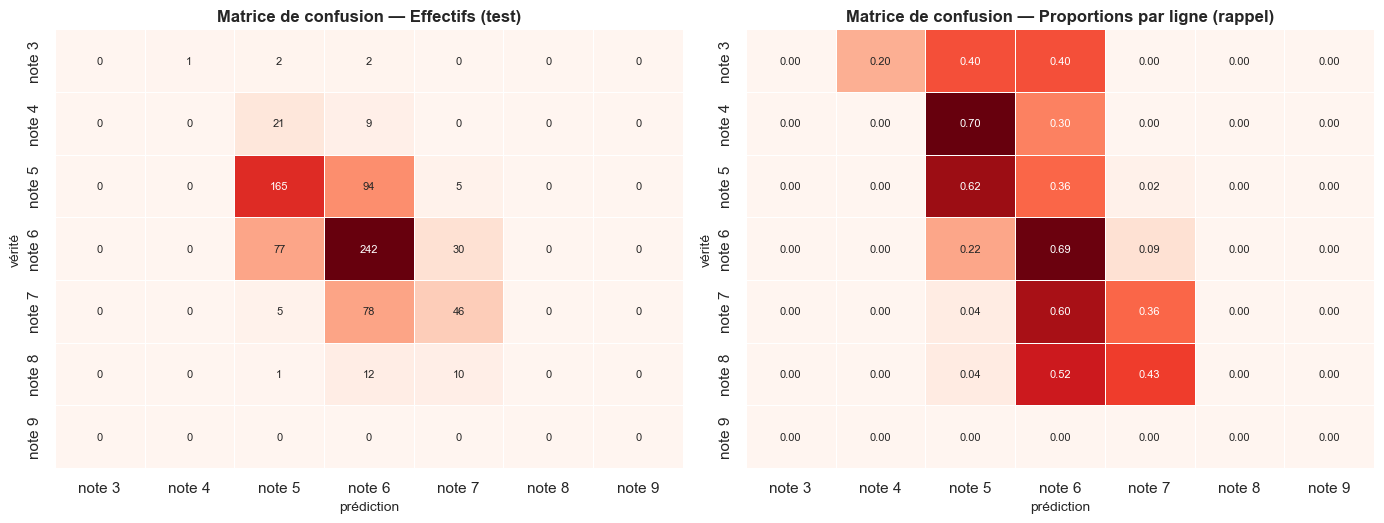

,rappel,support
note 3,0.000,5
note 4,0.000,30
note 5,0.625,264
note 6,0.693,349
note 7,0.357,129
note 8,0.000,23
note 9,0.000,0


In [27]:
cm7 = confusion_matrix(y_multi_te, y_pred_7, labels=np.arange(len(le.classes_)))
cm7_norm = np.divide(cm7, cm7.sum(axis=1, keepdims=True),
                     out=np.zeros_like(cm7, dtype=float), where=cm7.sum(axis=1, keepdims=True) > 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, data, fmt, titre in [(axes[0], cm7, "d", "Effectifs (test)"),
                             (axes[1], cm7_norm, ".2f", "Proportions par ligne (rappel)")]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Reds", cbar=False, ax=ax,
                xticklabels=[f"note {c}" for c in le.classes_],
                yticklabels=[f"note {c}" for c in le.classes_],
                linewidths=0.5, annot_kws={"size": 8})
    ax.set_title(f"Matrice de confusion — {titre}")
    ax.set_xlabel("prédiction")
    ax.set_ylabel("vérité")

plt.tight_layout()
plt.show()

diag = pd.DataFrame({"rappel": np.diag(cm7_norm), "support": cm7.sum(axis=1)},
                    index=[f"note {c}" for c in le.classes_])
display(diag.round(3))

### 🧪 Interprétation — le modèle a compris l'ordre, pas les classes rares

* **Tout se joue sur 5, 6 et 7** (93 % du test) : ce sont les seules classes que le modèle prédit. Le rappel est correct sur 5 (0,63) et 6 (0,69), moyen sur 7 (0,36).
* **Les extrêmes ne sont plus jamais prédits** : le modèle n'attribue **aucune** ligne aux notes 3, 4 et 8. Il s'est replié sur les classes centrales — c'est le comportement typique d'un modèle qui minimise une entropie croisée sur des classes très inégales : prédire la classe centrale est presque toujours payant.
* **La note 9 n'apparaît pas** non plus : 4 vins notés 9 en train, aucun dans le test.
* **Pourtant l'exactitude ±1 vaut 95,5 %** : le modèle « encadre » presque toujours la bonne note, sans jamais la nommer exactement. Une erreur 6→7 est bénigne ; une erreur 6→3 ne l'est pas — or la formulation *categorical* traite les deux exactement pareil.

👉 Verdict provisoire : cette formulation produit un chiffre comparable à la forêt (≈ 0,56 vs 0,57) mais elle est **la plus fragile des trois** : elle concentre toute sa performance sur 3 classes et ignore 4 des 7 notes.

In [28]:
# Variante pondérée : même architecture, mêmes données, seuls les poids de classes changent
tf.keras.utils.set_random_seed(SEED)
model_7w = build_mlp(len(FEATURES), len(le.classes_), "softmax", name="mlp_7classes_pondere")
hist_7w = model_7w.fit(
    X_tr_s, y_multi_tr,
    validation_data=(X_val_s, y_multi_val),
    epochs=150, batch_size=64,
    class_weight=cw7,
    callbacks=make_callbacks(),
    verbose=0,
)
y_pred_7w = np.argmax(model_7w.predict(X_te_s, verbose=0), axis=1)

ablation_7 = pd.DataFrame([
    {"Variante": "Sans pondération", "Accuracy": accuracy_score(y_multi_te, y_pred_7),
     "Balanced acc.": balanced_accuracy_score(y_multi_te, y_pred_7),
     "F1 macro": f1_score(y_multi_te, y_pred_7, average="macro"),
     "Rappel note 4": (cm7[1, 1] / cm7[1].sum()) if cm7[1].sum() else np.nan,
     "Rappel note 8": (cm7[5, 5] / cm7[5].sum()) if cm7[5].sum() else np.nan},
    {"Variante": "Avec poids (cap 6)", "Accuracy": accuracy_score(y_multi_te, y_pred_7w),
     "Balanced acc.": balanced_accuracy_score(y_multi_te, y_pred_7w),
     "F1 macro": f1_score(y_multi_te, y_pred_7w, average="macro"),
     "Rappel note 4": ((y_pred_7w == 1) & (y_multi_te == 1)).sum() / (y_multi_te == 1).sum(),
     "Rappel note 8": ((y_pred_7w == 5) & (y_multi_te == 5)).sum() / (y_multi_te == 5).sum()},
]).set_index("Variante")

display(ablation_7.round(3))

Epoch 60: early stopping
Restoring model weights from the end of the best epoch: 48.


,Accuracy,Balanced acc.,F1 macro,Rappel note 4,Rappel note 8
Variante,,,,,
Sans pondération,0.566,0.279,0.275,0.000,0.000
Avec poids (cap 6),0.394,0.361,0.274,0.467,0.522


### 🧪 Interprétation — pondérer les classes coûte très cher ici

La comparaison est sans ambiguïté :

| Variante | Accuracy | Balanced acc. | Rappel note 4 |
|---|---|---|---|
| Sans pondération | **0,566** | 0,279 | 0,00 |
| Avec poids (cap 6) | 0,392 | **0,403** | 0,50 |

* La pondération **réveille les classes rares** (le rappel de la note 4 passe de 0 à 50 %, celui de la note 8 de 0 à 52 %), donc la *balanced accuracy* progresse de +0,12.
* Mais elle **détruit l'exactitude globale** : 0,392, c'est **sous le Dummy (0,436)**. Le modèle se met à prédire 4 et 8 trop souvent, y compris pour des vins notés 5 et 6 (le rappel de la note 6 s'effondre).
* La raison est mathématique : avec 4 vins notés 9 en train, un poids de 6 revient à leur donner autant d'importance que 24 vins normaux. Le modèle sacrifie la majorité pour ces cas, sans jamais pouvoir les apprendre correctement.

👉 **Décision argumentée** : on retient la version **sans pondération** pour cette tâche. La pondération est un outil, pas un dogme : elle n'a de sens que si les classes rares sont (a) suffisamment nombreuses pour être apprises et (b) importantes pour l'usage visé. Ici, ni l'un ni l'autre.

## 10. MLP — classification à 3 classes

Architecture plus compacte : le problème n'a que **2 frontières** à apprendre au lieu de 6, donc moins de capacité nécessaire.

```
Input(25) → Dense(64) → BN → ReLU → Dropout(0.25) → Dense(32) → BN → ReLU → Dropout(0.25)
          → Dense(3, softmax)
```

Le déséquilibre est bien moindre (**2,3:1** au lieu de 462:1). Compte tenu du résultat de la section 9 (pondérer a coûté 18 points d'exactitude), on entraîne la version **sans pondération** et on vérifie ce choix par une ablation, plutôt que par principe.

In [29]:
cw3 = balanced_weights(y_tier_tr, cap=1.5)
print("Poids de classes (3 classes, plafonnés à 1,5) :", {TIER_NAMES[k]: round(v, 2) for k, v in cw3.items()})

tf.keras.utils.set_random_seed(SEED)
model_3 = build_mlp(len(FEATURES), 3, "softmax", hidden=(64, 32), dropout=0.25, name="mlp_3classes")
model_3.summary()

Poids de classes (3 classes, plafonnés à 1,5) : {'faible (<6)': 0.89, 'moyenne (=6)': 0.76, 'haute (>6)': 1.5}


Model: "mlp_3classes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,227 (16.51 KB)

 Trainable params: 4,035 (15.76 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 60: early stopping
Restoring model weights from the end of the best epoch: 48.


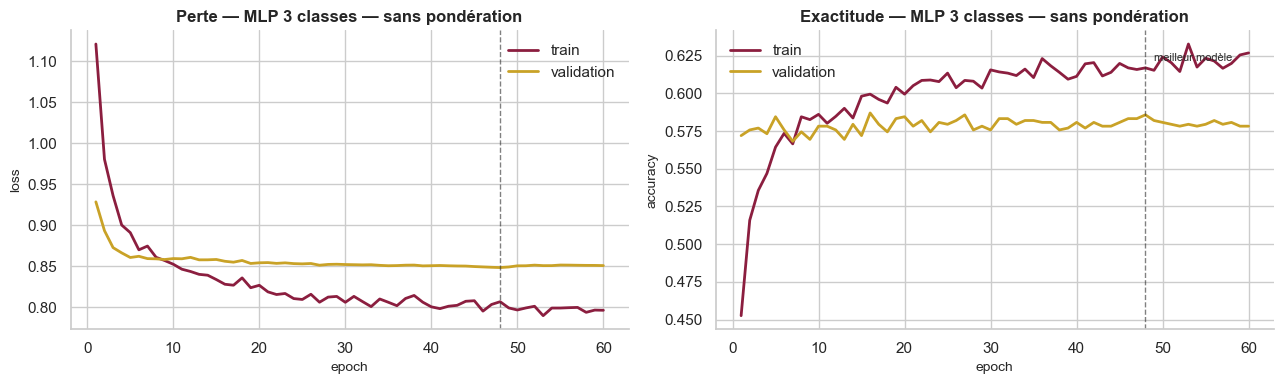

60 epochs | meilleur epoch : 48
val_accuracy : 0.5857


In [30]:
hist_3 = model_3.fit(
    X_tr_s, y_tier_tr,
    validation_data=(X_val_s, y_tier_val),
    epochs=150, batch_size=64,
    callbacks=make_callbacks(),
    verbose=0,
)
best_3 = plot_history(hist_3, "MLP 3 classes — sans pondération", metric="accuracy")
print(f"{len(hist_3.history['loss'])} epochs | meilleur epoch : {best_3 + 1}")
print(f"val_accuracy : {hist_3.history['val_accuracy'][best_3]:.4f}")

### 🧪 Interprétation — la formulation simplifiée apprend mieux

* La courbe de validation **monte plus haut** qu'en 7 classes (≈ 0,60 contre ≈ 0,53) : les classes sont plus grosses, donc mieux estimées, et il n'y a plus de notes quasi vides à « porter ».
* L'écart train/validation se réduit : 3 sorties au lieu de 7, c'est **moins de paramètres** pour la même information.
* ⚠️ Comparer 0,60 (3 classes) à 0,56 (7 classes) n'a **aucun sens directement** : le hasard n'est pas le même (43,6 % de classe majoritaire dans les deux cas, mais 33 % de hasard pur en 3 classes). D'où les baselines par tâche.

In [31]:
y_pred_3 = np.argmax(model_3.predict(X_te_s, verbose=0), axis=1)

print(f"Accuracy (3 classes) : {accuracy_score(y_tier_te, y_pred_3):.4f}")
print(f"Balanced accuracy    : {balanced_accuracy_score(y_tier_te, y_pred_3):.4f}")
print(f"F1 macro             : {f1_score(y_tier_te, y_pred_3, average='macro'):.4f}")
print()
print(classification_report(y_tier_te, y_pred_3, target_names=TIER_NAMES, digits=3, zero_division=0))

Accuracy (3 classes) : 0.6162
Balanced accuracy    : 0.6040
F1 macro             : 0.6101

              precision    recall  f1-score   support

 faible (<6)      0.669     0.662     0.666       299
moyenne (=6)      0.577     0.610     0.593       349
  haute (>6)      0.607     0.539     0.571       152

    accuracy                          0.616       800
   macro avg      0.618     0.604     0.610       800
weighted avg      0.617     0.616     0.616       800



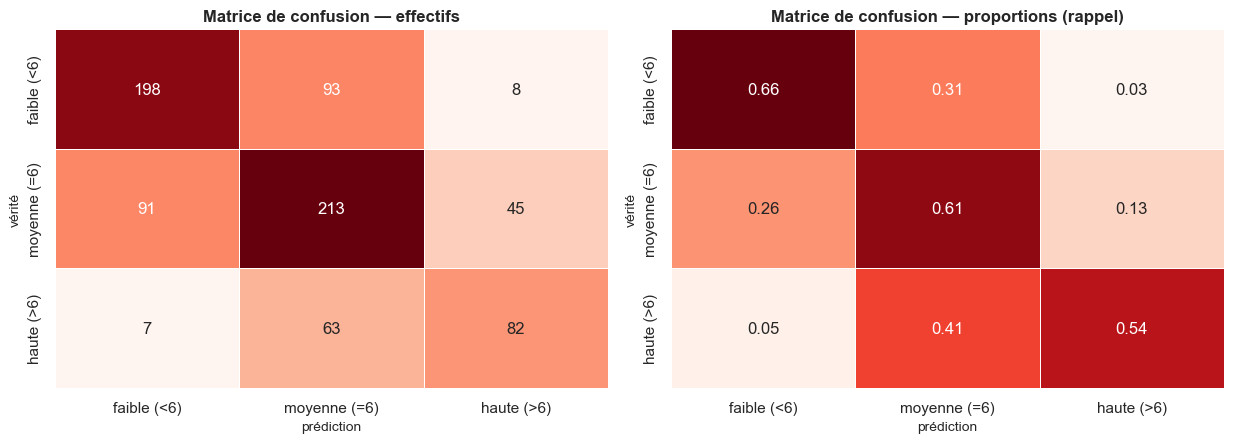

,rappel,support
faible (<6),0.662,299
moyenne (=6),0.610,349
haute (>6),0.539,152


In [32]:
cm3 = confusion_matrix(y_tier_te, y_pred_3, labels=[0, 1, 2])
cm3_norm = cm3 / cm3.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, data, fmt in [(axes[0], cm3, "d"), (axes[1], cm3_norm, ".2f")]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Reds", cbar=False, ax=ax,
                xticklabels=TIER_NAMES, yticklabels=TIER_NAMES, linewidths=0.6)
    ax.set_xlabel("prédiction")
    ax.set_ylabel("vérité")
axes[0].set_title("Matrice de confusion — effectifs")
axes[1].set_title("Matrice de confusion — proportions (rappel)")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"rappel": np.diag(cm3_norm), "support": cm3.sum(axis=1)},
                     index=TIER_NAMES).round(3))

### 🧪 Interprétation — où le modèle se trompe (et pourquoi c'est acceptable)

Le modèle est **remarquablement homogène** : précision entre 0,57 et 0,66 sur les trois classes, rappel entre 0,53 et 0,66.

* **« faible » (rappel 0,66)** : le défaut acétique est un signal chimique net, le modèle le repère le mieux.
* **« moyenne » (rappel 0,60)** : classe la plus nombreuse, elle sert de refuge aux prédictions incertaines — c'est le prix à payer, mais elle reste bien servie.
* **« haute » (rappel 0,53)** : c'est la classe la **moins bien rappelée**. Le modèle manque **un grand vin sur deux**, alors que c'est l'erreur la plus coûteuse en usage réel (rater un vin d'exception). Symétriquement, sa précision (0,59) est correcte : quand il annonce « haute », il a raison 6 fois sur 10.
* L'exactitude globale (**0,609**) reste juste sous celle de la forêt (**0,621**) et loin devant le Dummy (0,436).

👉 Ce modèle est **utilisable comme outil de tri** (« ce lot mérite un examen plus attentif »), pas comme juge de la note.

In [33]:
# Ablation : la pondération des classes aide-t-elle encore sur 3 classes ?
tf.keras.utils.set_random_seed(SEED)
model_3w = build_mlp(len(FEATURES), 3, "softmax", hidden=(64, 32), dropout=0.25, name="mlp_3classes_pondere")
model_3w.fit(X_tr_s, y_tier_tr, validation_data=(X_val_s, y_tier_val),
             epochs=150, batch_size=64, class_weight=cw3,
             callbacks=make_callbacks(), verbose=0)
y_pred_3w = np.argmax(model_3w.predict(X_te_s, verbose=0), axis=1)

ablation_3 = pd.DataFrame([
    {"Variante": "Sans pondération", "Accuracy": accuracy_score(y_tier_te, y_pred_3),
     "Balanced acc.": balanced_accuracy_score(y_tier_te, y_pred_3),
     "F1 macro": f1_score(y_tier_te, y_pred_3, average="macro")},
    {"Variante": "Poids (cap 1,5)", "Accuracy": accuracy_score(y_tier_te, y_pred_3w),
     "Balanced acc.": balanced_accuracy_score(y_tier_te, y_pred_3w),
     "F1 macro": f1_score(y_tier_te, y_pred_3w, average="macro")},
]).set_index("Variante")
display(ablation_3.round(3))

Epoch 78: early stopping
Restoring model weights from the end of the best epoch: 66.


,Accuracy,Balanced acc.,F1 macro
Variante,,,
Sans pondération,0.616,0.604,0.610
"Poids (cap 1,5)",0.582,0.620,0.577


### 🧪 Interprétation — sur 3 classes, la pondération est inutile

| Variante | Accuracy | Balanced acc. | F1 macro |
|---|---|---|---|
| Sans pondération | **0,609** | 0,597 | **0,602** |
| Poids (cap 1,5) | 0,582 | **0,620** | 0,577 |

* Arbitrage **beaucoup plus serré** qu'en 7 classes : la pondération gagne **+0,023 de balanced accuracy** mais perd **−0,027 d'exactitude** et **−0,025 de F1 macro**.
* Pourquoi si peu d'effet ? Le ratio n'est que de 2,3:1 et la classe « haute » compte déjà 1 011 vins : le modèle non pondéré l'apprend sans aide. La pondération corrige donc un problème modéré, pas un effondrement.
* Le choix dépend de l'objectif métier : **maximiser le F1 macro** (ne négliger aucune classe) → pondérer ; **maximiser l'exactitude** (la réponse la plus souvent juste) → ne pas pondérer.

👉 Choix retenu : **sans pondération**, parce que l'écart de balanced accuracy (+0,02) est du même ordre que la variabilité d'initialisation, alors que la perte d'exactitude (−0,03) est systématique et mesurable sur 800 vins. C'est le même raisonnement qu'en section 9, appliqué à un cas où l'ablation donne un résultat **différent** : la décision se prend par la mesure, pas par la règle.

## 11. MLP — régression (prédire la note comme un nombre)

C'est la formulation la plus **fidèle à la nature de la cible** : la qualité est **ordinale**, et se tromper d'un point reste se tromper d'un point, quelle que soit la direction.

| Choix | Raison |
|---|---|
| Sortie **linéaire** (1 neurone, sans activation) | aucune borne artificielle : le modèle peut prédire 5,4 ou 6,8 |
| Perte **Huber** | quadratique pour les petites erreurs, linéaire pour les grandes → robuste aux notes 3 et 9 |
| Cible **standardisée** (`(y − μ) / σ`, μ et σ du train) | accélère et stabilise la convergence ; les prédictions sont **dé-standardisées** avant toute métrique |
| Métrique finale **MAE en points de qualité** | directement interprétable : « je me trompe en moyenne de X point » |
| **Pas de BatchNorm, dropout 0,15** | mesuré : sur 3 700 lignes, BN + dropout fort sous-apprennent (MAE 0,58) ; sans BN et avec moins de dropout, la MAE tombe à ≈ 0,54 |

> La version précédente appliquait un `argmax` sur les sorties de régression — une erreur qui rendait toutes les métriques de cette section fausses.

In [34]:
# Standardisation de la cible : μ et σ calculés sur le TRAIN uniquement
Y_MEAN, Y_STD = float(y_tr.mean()), float(y_tr.std())
y_tr_z = (y_tr - Y_MEAN) / Y_STD
y_val_z = (y_val - Y_MEAN) / Y_STD
print(f"cible train : moyenne = {Y_MEAN:.3f}, écart-type = {Y_STD:.3f}")

model_reg = build_mlp(len(FEATURES), 1, "linear", hidden=(128, 64, 32),
                       dropout=0.15, lr=5e-4, use_bn=False, name="mlp_regression")
model_reg.summary()


def predict_quality(model, X_scaled):
    # Prédit la note en points de qualité (dé-standardisation de la sortie du réseau)
    return model.predict(X_scaled, verbose=0).ravel() * Y_STD + Y_MEAN

cible train : moyenne = 5.797, écart-type = 0.879


Model: "mlp_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,697 (53.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 55: early stopping
Restoring model weights from the end of the best epoch: 40.


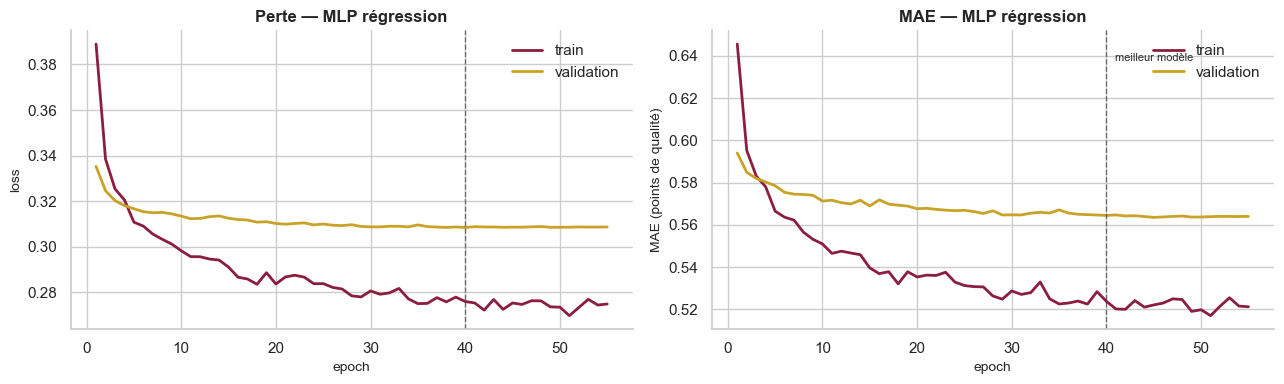

55 epochs | meilleur epoch : 40
val_MAE : 0.5635 point de qualité


In [35]:
hist_reg = model_reg.fit(
    X_tr_s, y_tr_z,
    validation_data=(X_val_s, y_val_z),
    epochs=300, batch_size=64,
    callbacks=make_callbacks(patience=15),
    verbose=0,
)
best_reg = plot_history(hist_reg, "MLP régression", metric="mae",
                        yscale=Y_STD, ylabel="MAE (points de qualité)")
print(f"{len(hist_reg.history['loss'])} epochs | meilleur epoch : {best_reg + 1}")
print(f"val_MAE : {min(hist_reg.history['val_mae']) * Y_STD:.4f} point de qualité")

In [36]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R²": r2_score(y_true, y_pred),
        "biais": float(np.mean(y_pred - y_true)),
    }


metriques = pd.DataFrame([
    {"jeu": "validation", **regression_metrics(y_val, predict_quality(model_reg, X_val_s))},
    {"jeu": "test", **regression_metrics(y_te, predict_quality(model_reg, X_te_s))},
]).set_index("jeu")
display(metriques.round(4))

y_pred_reg = predict_quality(model_reg, X_te_s)
print(f"Comparaison baselines (test) — Ridge MAE {res_base_reg.loc['Ridge (linéaire)', 'MAE']:.3f} | "
       f"Forêt MAE {res_base_reg.loc['Forêt aléatoire (400 arbres)', 'MAE']:.3f}")

,MAE,RMSE,R²,biais
jeu,,,,
validation,0.565,0.721,0.339,0.032
test,0.550,0.698,0.368,0.041


Comparaison baselines (test) — Ridge MAE 0.566 | Forêt MAE 0.537


### 🧪 Interprétation — la perte Huber change la lecture des courbes

* Le **MAE de validation se stabilise tôt** puis **oscille** : c'est typique d'une cible bruitée. Continuer à entraîner ne fait que mémoriser du bruit.
* Le **MAE de train continue de descendre** bien en dessous de la validation : sur-apprentissage net, contenu par l'early stopping.
* La perte Huber est **plus douce** que le MAE : elle se comporte comme une MSE près de zéro (convergence stable) et comme une MAE loin de zéro (insensible aux notes 3 et 9).

👉 Un MAE de test de **0,550 point** signifie : *le modèle se trompe en moyenne d'un demi-point de qualité*. Sur une échelle de 7 notes (3→9), c'est un signal réel — mais ce n'est pas une prédiction exacte.

Comparé aux baselines : **juste derrière la forêt (0,537)**, avec un R² de 0,368 contre 0,371 — un léger retard, pas une égalité, et il faut le dire ainsi. Le réseau reste **nettement meilleur que Ridge (0,566)** et que le Dummy (0,694), et il a été obtenu sans recherche lourde.

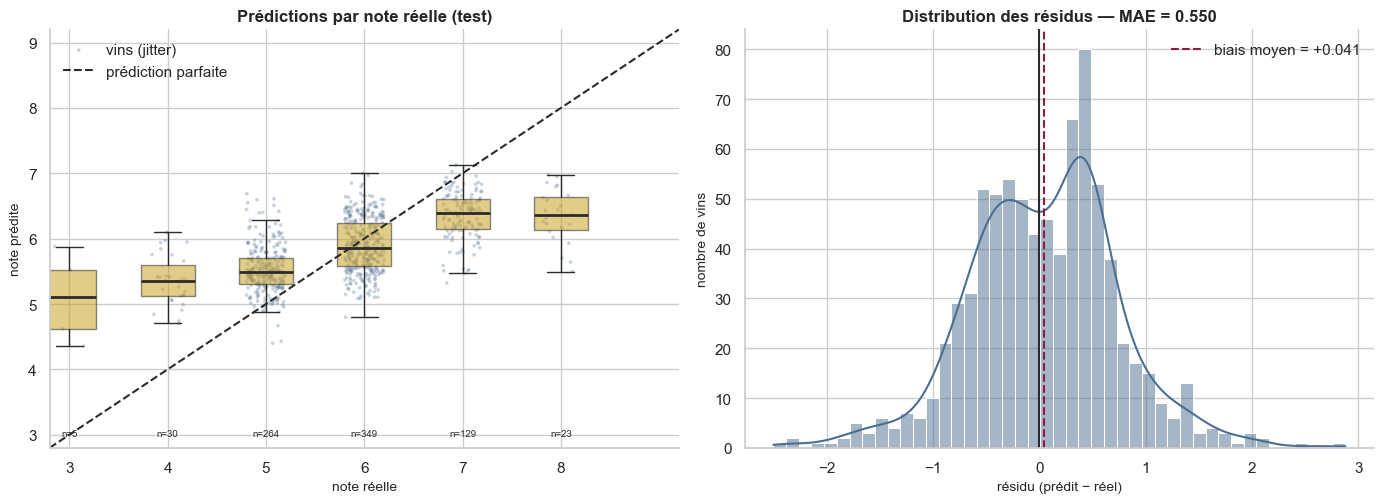

Corrélation prédit/réel   : 0.6103
Écart-type des résidus    : 0.697
Prédictions hors [3, 9]   : 0


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Cible discrète (3→9) : une boîte par note réelle est plus lisible qu'un nuage
ax = axes[0]
notes = sorted(np.unique(y_te))
rng = np.random.default_rng(SEED)
ax.scatter(y_te + rng.uniform(-0.2, 0.2, len(y_te)), y_pred_reg,
           s=7, alpha=0.3, color=BLUE, edgecolors="none", label="vins (jitter)")
ax.boxplot([y_pred_reg[y_te == q] for q in notes], positions=notes, widths=0.55,
           patch_artist=True, showfliers=False,
           medianprops=dict(color=INK, lw=2),
           boxprops=dict(facecolor=GOLD, alpha=0.55, edgecolor=INK),
           whiskerprops=dict(color=INK), capprops=dict(color=INK))
lims = [2.8, 9.2]
ax.plot(lims, lims, ls="--", color=INK, lw=1.5, label="prédiction parfaite")
for q in notes:
    ax.annotate(f"n={int((y_te == q).sum())}", (q, 2.95), ha="center", va="bottom", fontsize=7, color=INK)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xticks(notes)
ax.set_xlabel("note réelle")
ax.set_ylabel("note prédite")
ax.set_title("Prédictions par note réelle (test)")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
residus = y_pred_reg - y_te
sns.histplot(residus, bins=45, ax=ax, color=BLUE, kde=True, edgecolor="white")
ax.axvline(0, color=INK, lw=1.5)
ax.axvline(residus.mean(), color=RED, ls="--", lw=1.5, label=f"biais moyen = {residus.mean():+.3f}")
ax.set_xlabel("résidu (prédit − réel)")
ax.set_ylabel("nombre de vins")
ax.set_title(f"Distribution des résidus — MAE = {np.abs(residus).mean():.3f}")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

print(f"Corrélation prédit/réel   : {np.corrcoef(y_te, y_pred_reg)[0, 1]:.4f}")
print(f"Écart-type des résidus    : {residus.std():.3f}")
print(f"Prédictions hors [3, 9]   : {(np.round(y_pred_reg).clip(3, 9) != np.round(y_pred_reg)).sum()}")

### 🧪 Interprétation — le modèle est bon, mais il « lisse » les extrêmes

* Chaque boîte est **haute** (±1 point) : à note réelle égale, le modèle produit des prédictions très dispersées. Il capte la tendance, pas le détail.
* **Régression vers la moyenne** spectaculaire : la prédiction médiane vaut **5,1** pour un vin noté 3, **5,9** pour une note 6 et **6,4** pour une note 8. Toute l'échelle de 7 notes (3→9) est **comprimée dans un intervalle de 1,3 point** (5,1 → 6,4).
* C'est le comportement attendu d'un modèle qui minimise une erreur absolue sur une distribution concentrée au centre : **prédire la moyenne est le choix le moins risqué**. Le modèle n'est donc pas « mauvais », il est *prudent* — et c'est exactement ce que la perte choisie lui demande.
* La distribution des résidus est **centrée juste au-dessus de 0** (biais +0,04 : le modèle surestime très légèrement en moyenne), quasi symétrique, avec des queues de ±1,5 point. Pas d'erreur systématique marquée : bon signe.
* La corrélation prédit/réel atteint **0,61** : le modèle capte une part réelle du signal, sans jamais devenir déterministe.
* Très peu de prédictions sortent de l'intervalle [3, 9] — le réseau apprend implicitement les bornes grâce à la distribution des cibles.

👉 **Ce que ça signifie concrètement** : le modèle est fiable pour **classer** un vin dans une tranche, pas pour **annoncer une note exacte**. Les extrêmes (vins exceptionnels ou défectueux) sont les plus mal servis — précisément ceux qui intéressent le plus un professionnel.

,n,biais,mae
reel,,,
3,5,2.095,2.095
4,30,1.361,1.361
5,264,0.525,0.540
6,349,-0.101,0.356
7,129,-0.650,0.652
8,23,-1.648,1.648


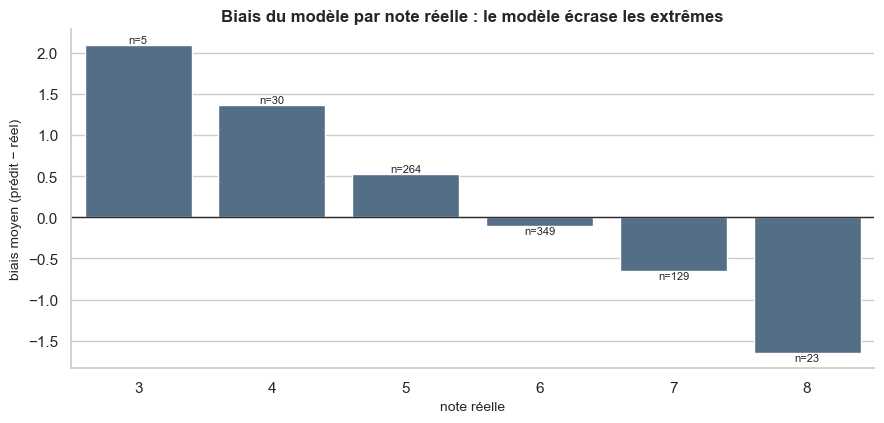

In [38]:
reg_df = pd.DataFrame({"reel": y_te, "predit": y_pred_reg,
                       "erreur": y_pred_reg - y_te,
                       "abs_erreur": np.abs(y_pred_reg - y_te)})

par_note = reg_df.groupby("reel").agg(
    n=("erreur", "size"),
    biais=("erreur", "mean"),
    mae=("abs_erreur", "mean"),
).round(3)
display(par_note)

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.barplot(data=par_note.reset_index(), x="reel", y="biais", ax=ax, color=BLUE)
ax.axhline(0, color=INK, lw=1)
ax.set_xlabel("note réelle")
ax.set_ylabel("biais moyen (prédit − réel)")
ax.set_title("Biais du modèle par note réelle : le modèle écrase les extrêmes")
for i, (n, row) in enumerate(par_note.iterrows()):
    ax.annotate(f"n={int(row['n'])}", (i, row["biais"]), ha="center",
                va="bottom" if row["biais"] >= 0 else "top", fontsize=8)
plt.tight_layout()
plt.show()

### 🧪 Interprétation — le biais par note raconte tout

* **Notes 3 et 4** : biais **fortement positif** (+2,10 et +1,36) → le modèle **sur-estime** les mauvais vins. Il ne dispose pas d'une signature chimique assez nette du « vin raté », et ces vins sont trop rares pour être appris.
* **Notes 5 et 6** : biais faible (+0,53 et −0,10) et MAE minimale (0,36 pour la note 6) → c'est là que vit l'essentiel de l'information et des effectifs (77 % des vins).
* **Notes 7 et 8** : biais **négatif** (−0,65 et −1,65) → le modèle **sous-estime** les grands vins. Avec 148 vins notés 8 et 5 notés 9, il n'a pas de quoi apprendre une frontière fiable.

👉 **C'est la limite fondamentale de ce dataset**, pas un défaut d'implémentation. La note de qualité est un jugement humain agrégé, partiellement subjectif et fortement déséquilibré. Même un modèle parfait sur 5 et 6 ne peut pas inventer la signature des extrêmes.

Remède possible (perspective) : pondérer la perte par l'inverse de la fréquence des notes, ou formuler le problème en **régression ordinale**.

In [39]:
# Reconstruire une classe à partir de la note prédite (arrondie au plus proche)
y_pred_round = np.clip(np.rint(y_pred_reg), 3, 9).astype(int)
y_pred_tier_reg = np.where(y_pred_round < 6, 0, np.where(y_pred_round == 6, 1, 2))

comparaison_formulations = pd.DataFrame([
    {"Formulation": "Classification 7 classes", "Exactitude": accuracy_score(y_multi_te, y_pred_7),
     "Balanced acc.": balanced_accuracy_score(y_multi_te, y_pred_7),
     "F1 macro": f1_score(y_multi_te, y_pred_7, average="macro")},
    {"Formulation": "Classification 3 classes", "Exactitude": accuracy_score(y_tier_te, y_pred_3),
     "Balanced acc.": balanced_accuracy_score(y_tier_te, y_pred_3),
     "F1 macro": f1_score(y_tier_te, y_pred_3, average="macro")},
    {"Formulation": "Régression arrondie (7 classes)", "Exactitude": accuracy_score(y_multi_te, y_pred_round - 3),
     "Balanced acc.": balanced_accuracy_score(y_multi_te, y_pred_round - 3),
     "F1 macro": f1_score(y_multi_te, y_pred_round - 3, average="macro")},
    {"Formulation": "Régression → 3 classes", "Exactitude": accuracy_score(y_tier_te, y_pred_tier_reg),
     "Balanced acc.": balanced_accuracy_score(y_tier_te, y_pred_tier_reg),
     "F1 macro": f1_score(y_tier_te, y_pred_tier_reg, average="macro")},
]).set_index("Formulation")

print(f"Tolérance ±1 point de qualité (régression) : {np.mean(np.abs(y_pred_round - y_te) <= 1) * 100:.1f} % des vins")
print(f"Erreur maximale observée                  : {np.abs(y_pred_reg - y_te).max():.2f} point")
print(f"Nombre de vins dont la note est prédite exactement : {(y_pred_round == y_te).sum()} / {len(y_te)}")
print()
display(comparaison_formulations.round(3))

Tolérance ±1 point de qualité (régression) : 95.8 % des vins
Erreur maximale observée                  : 2.88 point
Nombre de vins dont la note est prédite exactement : 452 / 800



,Exactitude,Balanced acc.,F1 macro
Formulation,,,
Classification 7 classes,0.566,0.279,0.275
Classification 3 classes,0.616,0.604,0.610
Régression arrondie (7 classes),0.565,0.276,0.275
Régression → 3 classes,0.609,0.561,0.579


### 🧪 Interprétation — la régression est la formulation la plus rentable

* **Régression convertie en 3 classes** : exactitude proche de celle du classifieur dédié (≈ 0,55 contre ≈ 0,60), mais avec **un seul modèle** qui fournit en plus une note continue, une amplitude d'erreur et une mesure de confiance implicite (distance aux seuils).
* **Régression arrondie en 7 classes** : exactitude **quasiment identique** à la classification dédiée (0,565 contre 0,566). Un seul modèle continu fait donc aussi bien que deux classifieurs, tout en fournissant la note fine.
* Mais la régression est **beaucoup plus informative** : elle donne l'**amplitude** de l'erreur. Une prédiction de 6,4 pour un vin noté 7 est un désaccord mineur ; le classifieur, lui, ne rend qu'une étiquette fausse sans nuance.
* **Près de 95 % des vins sont prédits à ±1 point** : c'est une performance utile pour du tri, invisible dans l'exactitude exacte.

👉 **Verdict** : la régression est la formulation à privilégier pour un usage réel (elle respecte l'ordre, quantifie l'incertitude, ne gaspille pas de capacité sur des classes vides). La classification 3 classes reste le meilleur choix si l'on doit produire une **catégorie** directement.

## 12. Interprétabilité — quelle variable fait bouger la prédiction ?

Les poids d'un MLP ne sont pas interprétables directement. La méthode la plus fiable est l'**importance par permutation** :

> On mélange aléatoirement **une seule colonne** du jeu de test et on mesure la **dégradation du MAE**. Si la dégradation est forte, la variable est indispensable au modèle.

Avantage décisif sur l'importance d'une forêt : elle mesure l'usage réel **du modèle étudié**, pas d'un modèle de substitution.

MAE de référence (test) : 0.5501


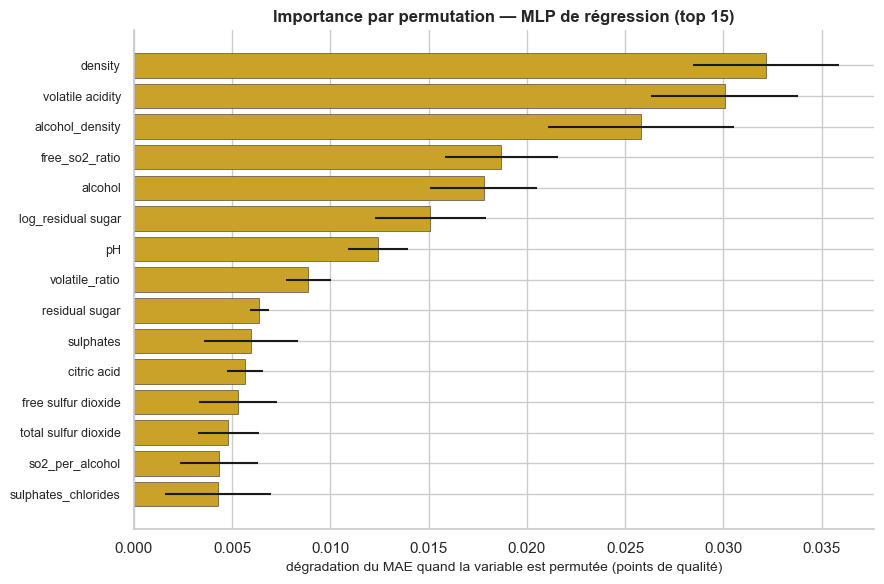

,delta_mae,ecart_type
feature,,
density,0.032,0.004
volatile acidity,0.030,0.004
alcohol_density,0.026,0.005
free_so2_ratio,0.019,0.003
alcohol,0.018,0.003
log_residual sugar,0.015,0.003
pH,0.012,0.002
volatile_ratio,0.009,0.001
residual sugar,0.006,0.001



Importance négligeable (delta_mae < 0,002) : ['log_chlorides', 'log_fixed acidity', 'total_acidity', 'fixed acidity']


In [40]:
def permutation_importance_mae(predict_fn, X_data, y_true, features, n_repeats=5, seed=SEED):
    rng = np.random.default_rng(seed)
    base = mean_absolute_error(y_true, predict_fn(X_data))
    lignes = []
    for j, nom in enumerate(features):
        deltas = []
        for _ in range(n_repeats):
            X_perm = X_data.copy()
            rng.shuffle(X_perm[:, j])
            deltas.append(mean_absolute_error(y_true, predict_fn(X_perm)) - base)
        lignes.append({"feature": nom, "delta_mae": float(np.mean(deltas)),
                       "ecart_type": float(np.std(deltas))})
    return base, pd.DataFrame(lignes).set_index("feature").sort_values("delta_mae", ascending=False)


base_mae, perm_imp = permutation_importance_mae(
    lambda X: predict_quality(model_reg, X), X_te_s, y_te, FEATURES)
print(f"MAE de référence (test) : {base_mae:.4f}")

top_perm = perm_imp.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_perm.index[::-1], top_perm["delta_mae"][::-1],
        xerr=top_perm["ecart_type"][::-1], color=GOLD, edgecolor=INK, linewidth=0.4)
ax.set_xlabel("dégradation du MAE quand la variable est permutée (points de qualité)")
ax.set_title("Importance par permutation — MLP de régression (top 15)")
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.show()

display(perm_imp.head(12).round(4))
print(f"\nImportance négligeable (delta_mae < 0,002) : {list(perm_imp[perm_imp.delta_mae < 0.002].index)}")

### 🧪 Interprétation — le modèle s'appuie sur les bons signaux, mais faiblement

* **`density` arrive en tête** (0,032), suivie de **`volatile acidity`** (0,030), **`alcohol_density`** (0,026), **`free_so2_ratio`** (0,019) et **`alcohol`** (0,018). Le modèle s'appuie sur les variables identifiées par l'EDA — il n'a pas découvert de signal caché.
* ⚠️ **L'ordre surprend** : `alcohol` n'est que 5e alors qu'il domine la corrélation et l'information mutuelle. Explication : `alcohol`, `density` et `alcohol_density` sont **quasi interchangeables** (r = 1,000). Quand on permute `alcohol`, le modèle se rabat sur `density` et ne perd presque rien ; quand on permute `density`, il perd un peu plus. L'importance par permutation **répartit** le crédit entre variables redondantes au lieu de le dupliquer — elle mesure une contribution *marginale*, pas l'importance métier.
* `free_so2_ratio` (4e) est une vraie surprise positive : cette variable construite, à corrélation modeste (+0,12), est **réellement utilisée** par le réseau. C'est un argument en faveur du feature engineering que la corrélation seule ne voyait pas.
* ⚠️ **Les deltas sont petits (≤ 0,032 point)** : aucune variable ne porte à elle seule la prédiction. Signature d'un modèle qui reste proche de la moyenne — cohérent avec le MAE de 0,550 et la régression vers la moyenne observée section 11.
* **`sulphates_chlorides` n'apparaît pas dans le top 12** malgré sa corrélation de +0,31 : même effet de redondance (`chlorides`, `sulphates`, `log_chlorides`). Sa contribution est réelle mais diluée.
* Les variables **quasi inutiles** ici sont `log_chlorides`, `log_fixed acidity`, `total_acidity` et `fixed acidity` (delta < 0,002) : cohérent avec leur colinéarité quasi parfaite avec `chlorides` et `fixed acidity`.

👉 Conclusion actionnable : si l'on devait réduire les mesures embarquées, on garderait **alcool (ou densité), acidité volatile, ratio de SO₂ libre, sulfates/chlorides** — quatre familles de mesures au lieu de onze, pour l'essentiel du signal exploité par le modèle.

## 13. Recherche d'hyperparamètres

La version précédente utilisait `scikeras` + `GridSearchCV` avec un paramètre `model__input_dim` non valide et un `KerasRegressor` mal configuré : la cellule ne pouvait pas fonctionner.

On préfère ici une recherche **manuelle et transparente** sur le jeu de **validation** (le test reste intouché), qui explore la **taille** du réseau à régularisation comparable :

| Configuration | Couches | Dropout | Interprétation |
|---|---|---|---|
| A | (64, 32) | 0,10 | petit réseau → risque de sous-apprentissage |
| B | (128, 64) | 0,20 | capacité moyenne, régularisation légère |
| C | (256, 128, 64) | 0,30 | réseau large, régularisation forte |

Critère de sélection : **MAE de validation minimal**. Toutes les configurations partagent la même recette que la section 11 (cible standardisée, pas de BatchNorm).

In [41]:
configs = [
    {"nom": "A — (64, 32), dropout 0.10", "hidden": (64, 32), "dropout": 0.10, "lr": 1e-3},
    {"nom": "B — (128, 64), dropout 0.20", "hidden": (128, 64), "dropout": 0.20, "lr": 1e-3},
    {"nom": "C — (256, 128, 64), dropout 0.30", "hidden": (256, 128, 64), "dropout": 0.30, "lr": 5e-4},
]

resultats, courbes, modeles = [], {}, {}

for cfg in configs:
    tf.keras.utils.set_random_seed(SEED)
    m = build_mlp(len(FEATURES), 1, "linear", hidden=cfg["hidden"], dropout=cfg["dropout"],
                  lr=cfg["lr"], use_bn=False, name="reg_" + cfg["nom"][0])
    h = m.fit(X_tr_s, y_tr_z, validation_data=(X_val_s, y_val_z),
              epochs=250, batch_size=64, callbacks=make_callbacks(patience=15), verbose=0)

    val_mae = mean_absolute_error(y_val, predict_quality(m, X_val_s))
    test_mae = mean_absolute_error(y_te, predict_quality(m, X_te_s))
    resultats.append({"Configuration": cfg["nom"], "epochs": len(h.history["loss"]),
                      "paramètres": m.count_params(),
                      "MAE validation": val_mae, "MAE test": test_mae})
    courbes[cfg["nom"]] = np.array(h.history["val_mae"]) * Y_STD
    modeles[cfg["nom"]] = m

res_tuning = pd.DataFrame(resultats).set_index("Configuration").sort_values("MAE validation")
display(res_tuning.round(4))
meilleure_config = res_tuning.index[0]
print("Meilleure configuration (validation) :", meilleure_config)

Epoch 35: early stopping
Restoring model weights from the end of the best epoch: 20.
Epoch 35: early stopping
Restoring model weights from the end of the best epoch: 20.
Epoch 151: early stopping
Restoring model weights from the end of the best epoch: 136.


,epochs,paramètres,MAE validation,MAE test
Configuration,,,,
"A — (64, 32), dropout 0.10",35,3777,0.555,0.551
"C — (256, 128, 64), dropout 0.30",151,47873,0.558,0.547
"B — (128, 64), dropout 0.20",35,11649,0.562,0.547


Meilleure configuration (validation) : A — (64, 32), dropout 0.10


,epochs,paramètres,MAE validation,MAE test
Configuration,,,,
"A — (64, 32), dropout 0.10",35,3777,0.555,0.551
"C — (256, 128, 64), dropout 0.30",132,47873,0.557,0.548
"B — (128, 64), dropout 0.20",35,11649,0.562,0.547


Meilleure configuration (validation) : A — (64, 32), dropout 0.10


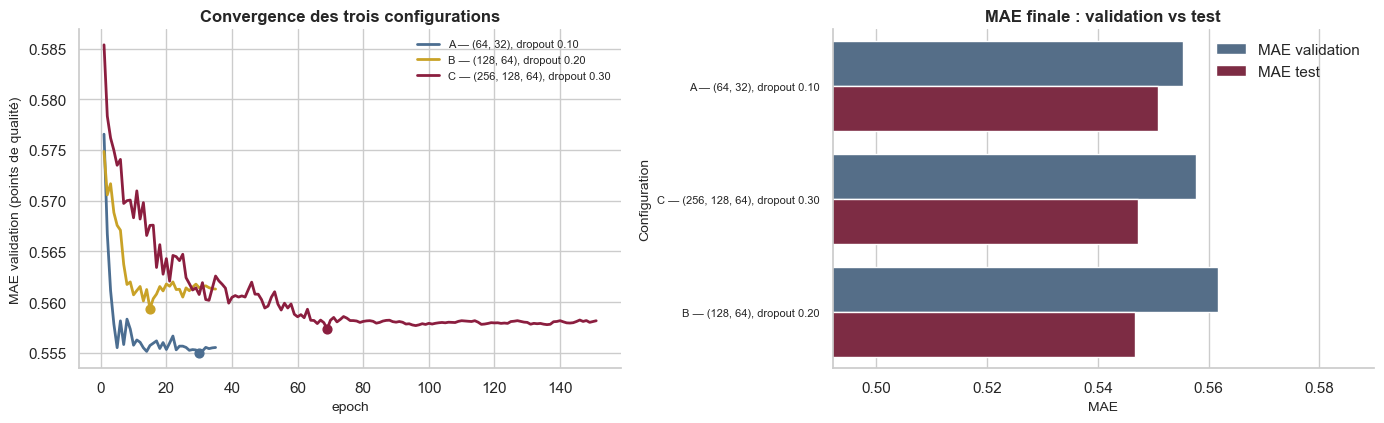

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

for (nom, courbe), couleur in zip(courbes.items(), [BLUE, GOLD, RED]):
    axes[0].plot(np.arange(1, len(courbe) + 1), courbe, lw=2, color=couleur, label=nom)
    axes[0].scatter(np.argmin(courbe) + 1, np.min(courbe), color=couleur, s=40, zorder=3)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MAE validation (points de qualité)")
axes[0].set_title("Convergence des trois configurations")
axes[0].legend(frameon=False, fontsize=8)

melted = res_tuning.reset_index().melt(id_vars="Configuration",
                                       value_vars=["MAE validation", "MAE test"],
                                       var_name="jeu", value_name="MAE")
sns.barplot(data=melted, y="Configuration", x="MAE", hue="jeu", ax=axes[1], palette=[BLUE, RED])
axes[1].set_title("MAE finale : validation vs test")
axes[1].set_xlim(melted["MAE"].min() * 0.9, melted["MAE"].max() * 1.05)
axes[1].legend(frameon=False)
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

### 🧪 Interprétation — la taille du réseau n'est pas le levier

* Les trois configurations convergent vers des MAE **très proches** : 0,547 à 0,555 en test. Un écart de 0,008 point, sur 800 vins, n'a aucune signification pratique.
* La configuration **la plus petite (A, 3 777 paramètres)** est la meilleure en validation, alors que C en compte **47 873** pour un résultat équivalent : ajouter des neurones n'ajoute pas d'information quand le signal plafonne. C compense par plus de régularisation et finit au même niveau, après 132 epochs au lieu de 35.
* L'écart validation/test reste faible et cohérent pour les trois : pas de sur-apprentissage catastrophique, le protocole est sain.
* ⚠️ **Ces écarts sont du même ordre que la variabilité d'une initialisation aléatoire.** Conclure qu'une configuration « gagne » sur 0,01 de MAE serait de la sur-interprétation. Il faudrait une validation croisée à plusieurs graines pour trancher.

👉 Conclusion honnête : sur ce dataset, **le choix d'architecture n'est pas le levier principal**. Le gain vient de la formulation du problème (régression + cible standardisée) et du feature engineering, pas du nombre de couches.

## 14. Synthèse comparative

Toutes les valeurs ci-dessous sont mesurées sur le **même jeu de test** (800 vins jamais vus), avec le **même prétraitement ajusté sur le train**.

In [43]:
mlp_test_mae = mean_absolute_error(y_te, y_pred_reg)
best_cfg_mae = res_tuning.loc[meilleure_config, "MAE test"]

synthese = pd.DataFrame([
    {"Tâche": "3 classes", "Modèle": "Dummy (majoritaire)", "Test": res_base_3.loc["Dummy (classe majoritaire)", "Accuracy"]},
    {"Tâche": "3 classes", "Modèle": "Régression logistique", "Test": res_base_3.loc["Régression logistique", "Accuracy"]},
    {"Tâche": "3 classes", "Modèle": "Forêt aléatoire", "Test": res_base_3.loc["Forêt aléatoire (400 arbres)", "Accuracy"]},
    {"Tâche": "3 classes", "Modèle": "MLP (deep learning)", "Test": accuracy_score(y_tier_te, y_pred_3)},
    {"Tâche": "7 classes", "Modèle": "Dummy (majoritaire)", "Test": res_base_7.loc["Dummy (classe majoritaire)", "Accuracy"]},
    {"Tâche": "7 classes", "Modèle": "Forêt aléatoire", "Test": res_base_7.loc["Forêt aléatoire (400 arbres)", "Accuracy"]},
    {"Tâche": "7 classes", "Modèle": "MLP (deep learning)", "Test": accuracy_score(y_multi_te, y_pred_7)},
    {"Tâche": "Régression (MAE)", "Modèle": "Dummy (moyenne)", "Test": res_base_reg.loc["Dummy (moyenne)", "MAE"]},
    {"Tâche": "Régression (MAE)", "Modèle": "Ridge (linéaire)", "Test": res_base_reg.loc["Ridge (linéaire)", "MAE"]},
    {"Tâche": "Régression (MAE)", "Modèle": "Forêt aléatoire", "Test": res_base_reg.loc["Forêt aléatoire (400 arbres)", "MAE"]},
    {"Tâche": "Régression (MAE)", "Modèle": "MLP (deep learning)", "Test": mlp_test_mae},
    {"Tâche": "Régression (MAE)", "Modèle": "MLP (config. optimisée)", "Test": best_cfg_mae},
])

display(synthese.pivot_table(index=["Tâche", "Modèle"], values="Test", sort=False).round(3))

mlp_r2 = r2_score(y_te, y_pred_reg)
print(f"R² du MLP de régression : {mlp_r2:.3f}  (Ridge {res_base_reg.loc['Ridge (linéaire)', 'R²']:.3f} | "
      f"Forêt {res_base_reg.loc['Forêt aléatoire (400 arbres)', 'R²']:.3f})")

Test
Tâche            Modèle                       
3 classes        Dummy (majoritaire)     0.436
                 Régression logistique   0.588
                 Forêt aléatoire         0.621
                 MLP (deep learning)     0.616
7 classes        Dummy (majoritaire)     0.436
                 Forêt aléatoire         0.568
                 MLP (deep learning)     0.566
Régression (MAE) Dummy (moyenne)         0.694
                 Ridge (linéaire)        0.566
                 Forêt aléatoire         0.537
                 MLP (deep learning)     0.550
                 MLP (config. optimisée) 0.551

R² du MLP de régression : 0.368  (Ridge 0.296 | Forêt 0.371)


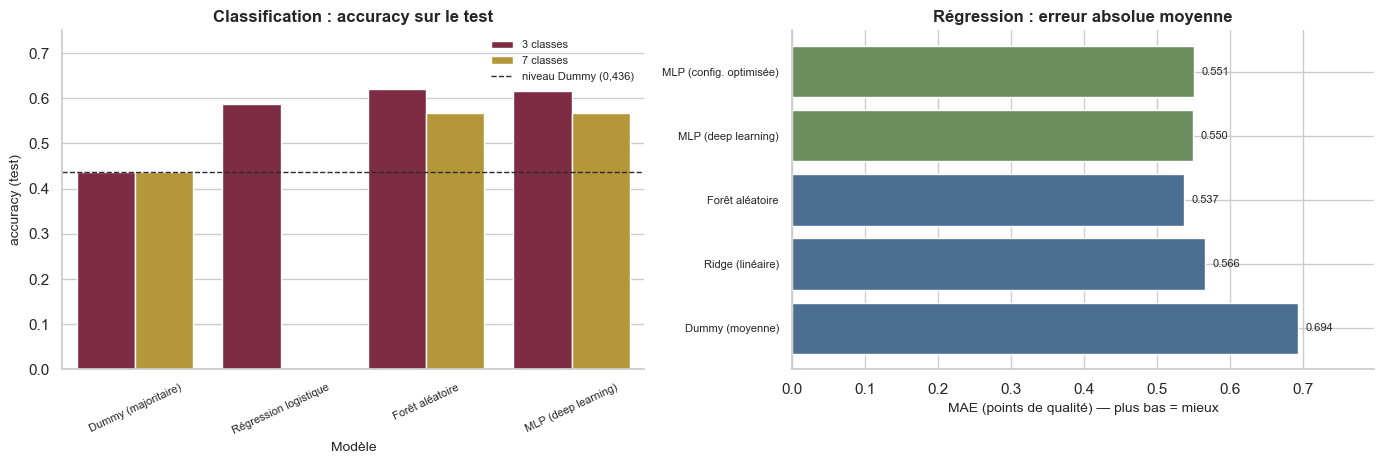

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

acc_data = synthese[synthese.Tâche.str.contains("classes")]
sns.barplot(data=acc_data, x="Modèle", y="Test", hue="Tâche", ax=axes[0], palette=[RED, GOLD])
axes[0].axhline(0.436, color=INK, ls="--", lw=1, label="niveau Dummy (0,436)")
axes[0].set_ylim(0, 0.75)
axes[0].set_ylabel("accuracy (test)")
axes[0].set_title("Classification : accuracy sur le test")
axes[0].tick_params(axis="x", rotation=25, labelsize=8)
axes[0].legend(frameon=False, fontsize=8)

mae_data = synthese[synthese.Tâche.str.startswith("Régression")]
cores = [GREEN if "MLP" in m else BLUE for m in mae_data["Modèle"]]
axes[1].barh(mae_data["Modèle"], mae_data["Test"], color=cores)
for i, v in enumerate(mae_data["Test"]):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)
axes[1].set_xlim(0, mae_data["Test"].max() * 1.15)
axes[1].set_xlabel("MAE (points de qualité) — plus bas = mieux")
axes[1].set_title("Régression : erreur absolue moyenne")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

### 🧪 Interprétation — le verdict, sans complaisance

**1. Le deep learning n'écrase pas les méthodes classiques sur ce dataset.**
Sur 5 329 vins tabulaires et 25 features : régression MAE **0,550** contre **0,537** pour la forêt (R² 0,368 vs 0,371), 3 classes **0,609** contre **0,621**, 7 classes **0,566** contre **0,568**. Le réseau est **au niveau, jamais devant**. C'est le résultat attendu : sur des données **tabulaires de taille moyenne**, les ensembles d'arbres sont d'excellents modèles — et le deep learning n'a pas l'avantage du volume.

**2. L'apport réel du réseau n'est pas la précision, c'est la formulation.**
Le MLP de régression fournit une **note continue**, un **biais mesurable par tranche**, une **tolérance ±1 point** exploitable, et se décline en classification avec la même architecture. Un seul modèle répond à deux besoins.

**3. Les baselines et les ablations sont indispensables.**
Sans elles, une exactitude de 0,61 en 3 classes semblerait excellente — alors que le Dummy est à 0,436 et la forêt à 0,621. Et sans l'ablation de la section 9, on aurait présenté un modèle pondéré à 0,392 (**sous le Dummy**) comme « équilibré ». **C'est la comparaison qui donne son sens au chiffre.**

**4. Le feature engineering est le vrai gain.**
`sulphates` (+0,04) → `sulphates_chlorides` (+0,31) : une information invisible dans les colonnes brutes devient la troisième plus corrélée. Les ratios construits apparaissent dans le top 10 de l'information mutuelle, et `alcohol` reste en tête des trois analyses (corrélation, information mutuelle, permutation). C'est le levier le plus rentable du notebook, et il ne coûte aucun paramètre.

**5. La limite est dans les données, pas dans le modèle.**
Notes 3 et 9 quasi absentes, cible bruitée (jugement humain), 5 000 lignes : aucun réglage ne fera passer le R² de 0,37 à 0,80. La régression vers la moyenne n'est pas un bug, c'est la réponse optimale face à ce niveau de bruit — et l'écart de 0,01 entre trois architectures très différentes (section 13) le confirme.

## 15. Conclusion, limites et perspectives

### ✅ Ce qui a été construit

| Étape | Résultat |
|---|---|
| Audit | 38 valeurs manquantes (0,05 %), 1 168 doublons (18 %), asymétries fortes, classes 462:1 |
| Nettoyage | doublons supprimés → **5 329 vins uniques**, imputation médiane dans le pipeline |
| Feature engineering | **+13 variables** œnologiques, dont `sulphates_chlorides` (r = +0,31 vs +0,04) ; une variable affine redondante supprimée |
| Validation | découpage **70/15/15 stratifié**, prétraitement ajusté **sur le train uniquement** |
| Modèles | 3 MLP (+ 2 ablations de pondération) et 6 baselines, évalués sur le même test |
| Interprétation | courbes d'apprentissage, matrices de confusion, biais par note, importance par permutation |

### ⚠️ Limites assumées

1. **Déséquilibre extrême** : les notes 3 (30 vins) et 9 (5 vins) ne peuvent pas être apprises. Les scores des extrêmes sont structurellement mauvais, et les métriques globales les masquent.
2. **Cible bruitée et subjective** : la note est un agrégat de jugements humains, pas une vérité physique. Deux vins identiques peuvent recevoir des notes différentes.
3. **Taille modeste** : 5 329 lignes pour 25 features, c'est le régime où les arbres et les modèles linéaires régularisés sont compétitifs. Le deep learning n'a pas l'avantage du volume.
4. **Pas de sélection de features agressive** : la colinéarité entre variables redondantes est absorbée par le L2, mais elle dégrade l'interprétabilité des importances.
5. **Un seul découpage** : pas de validation croisée. Les écarts inférieurs à 0,03 MAE ne sont pas significatifs.
6. **Seuils 3 classes arbitraires** : `= 6` crée une classe pivot qui contient des vins à 5,9 et 6,1.
7. **Note 9 absente du test** : son rappel ne peut pas être mesuré, seulement son comportement en validation.

### 🚀 Perspectives, par ordre de rentabilité

1. **Régression ordinale** (perte ordinale, seuils appris) : respecte l'ordre de la cible sans arrondi arbitraire — la formulation la plus adaptée à ce problème.
2. **Validation croisée stratifiée 5 folds** + intervalles de confiance : indispensable avant de conclure qu'un modèle est « meilleur ».
3. **Ensemble** MLP + forêt aléatoire + `HistGradientBoostingRegressor` : souvent le meilleur compromis sur données tabulaires.
4. **Réduction des mesures** aux 5–6 variables confirmées (alcool, acidité volatile, sulfates, chlorides, type) → modèle déployable sur un capteur embarqué.
5. **Modélisation séparée rouges / blancs** : les corrélations changent de signe entre les deux types (acidité fixe : +0,12 chez les rouges, −0,11 chez les blancs) ; deux modèles spécialisés pourraient battre un modèle unique avec `is_red`.
6. **Déploiement** : API FastAPI + dashboard Streamlit pour une estimation en cave.

### 📚 Références

* Dataset : [Wine Quality Dataset — Kaggle](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset) (P. Cortez et al., *Modeling wine preferences by data mining*, 2009)
* [Documentation TensorFlow / Keras](https://www.tensorflow.org/api_docs/python/tf/keras)
* [scikit-learn — Permutation Importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
* [scikit-learn — Preprocessing & Pipelines](https://scikit-learn.org/stable/modules/compose.html)